# Impedance Match For UCD SiO$_2$ Data




In [1]:
%run -i ../scripts/load_modules
# modules not used in main jupyterbook
# Impedance Match Calculation classes and functions
import IM_module as IM # classes and functions for this impedance match notebook
import pandas as pd
from scipy import linalg
from copy import deepcopy

# needed form impedance matching
# Collect files needed to run this notebook in the cloud (e.g., Google CoLab)
use_local_files = True # prefer local files than GitHub repo (change to false to refresh from repo)
import os
from os.path import exists

print("Date and time: ", datetime.datetime.now())


Date and time:  2026-03-23 09:31:06.940577


## Choose load pickle file or re-run Monte Carlo Impedance Match

Set number of MC iterations.

N=1000 run used for error bars and plots at the bottom.


In [2]:
# Run the MC again
#RUNMC = True
# Load the pickle file; do not run; set to False to compile the Jupyterbook
RUNMC = False

# set number of IM calcs
#N=50
N=1000


## Load the material database

Updated July 2024 to include Cu101 fit and covariance matrix for shot 50.

In [3]:
# load the materials data table; change matfilename if not using default
matdata, imat = IM.ReadMaterials(matfilename='materials-data.csv')

display(matdata)

,Material,Density(kg/m3),rho0_err,c0(m/s),c0_err,s1,s1_err,s2(s/m),s2_err,d(s/m),d_err,g0,g0_err,q,q_err,up_low(m/s),up_high(m/s),IHED_id,Date,Notes
0,Steel304-l2,7870.0,-1,4580.00000,-1,1.490000,-1,0.000000,-1,0.000000,0,2.20,-1,1.00,-1,170.0,3607.0,347,9/4/23,STS refit Duffy+IHED RECOMMENDED
1,Fused-qtz-stv,2204.0,-1,1107.26163,-1,1.606945,-1,0.000000,0,0.000000,0,0.65,-1,1.00,-1,2800.0,4000.0,143,5/13/25,STS fit to stv region RECOMMENDED
2,Fused-qtz-stv-old,2204.0,-1,1382.81770,-1,1.535125,-1,0.000000,0,0.000000,0,0.65,-1,1.00,-1,2800.0,4000.0,143,9/4/23,STS fit to stv region
3,qtz-CaCl2-region-old,2650.0,-1,1797.25088,-1,1.688354,-1,0.000000,-1,0.000000,0,1.00,-1,1.00,-1,0.0,-1.0,174,9/4/23,Stewart fit CaCl2 region 2023
4,Aluminium 6061,2683.0,-1,5349.00000,-1,1.338000,-1,0.000000,-1,0.000000,0,1.00,-1,1.00,-1,-1.0,-1.0,324,11/11/22,Duffy & Ahrens 1998 NEED TO ADD Z data
5,Steel 304,7870.0,-1,4580.00000,-1,1.490000,-1,0.000000,-1,0.000000,0,2.20,-1,1.00,-1,209.0,1485.0,347,11/11/22,Duffy & Ahrens 1998
6,Steel304-q,7870.0,-1,4579.00000,-1,1.533428,-1,-0.000014,-1,0.000000,0,2.20,-1,1.00,-1,170.0,4730.0,347,11/11/22,STS refit Duffy+IHED 9/4/2023 NOT RECOMMENDED
7,Copper,8924.0,-1,3975.00000,-1,1.471000,-1,-0.000005,-1,0.000000,0,1.96,-1,1.00,-1,0.0,40800.0,45,11/11/22,IHED fit; g0 Gilev 2018 and q is quess
8,Tantalum,16649.0,-1,3310.00000,-1,1.306000,-1,0.000000,-1,0.000000,0,1.62,-1,1.00,-1,0.0,-1.0,75,11/11/22,AGU Reference Shelf+Katahara et al. 1979+Cohen...
9,Tungsten,19235.0,-1,3994.00000,-1,1.278800,-1,-0.000005,-1,0.000000,0,1.81,-1,0.71,-1,0.0,16450.0,79,11/11/22,IHED fit and Litasov 2013 for gamma


## Set up the materials and uncertainties - MKS UNITS

covariance matrices are from Hugoniot fits

currently all linear fits -- need to update IM_module for other forms

<bold>mat3 needs correct density and uncertainty in the material initialization</bold>


In [4]:
# everything in mks

# set up independent particle velocity array
up =np.arange(501)/500*10000

# initialize materials used in this notebook
# flyer
SS304a = IM.Material() # create material object named 'mat3'
matname='Steel304-l2' # material name in the material-data.csv file
SS304a.DefineParamsID(matname,matdata,imat) # load the parameters for this material
SS304a.MakeHugoniot(up)
SS304a.rho0_err = 10
SS304a.cov = np.asarray([[ 2.85192390e-05, -3.54779333e-02], [-3.54779333e-02,  6.52812465e+01]])
SS304a.lmat = linalg.cholesky(SS304a.cov,lower=True)

# driver
SS304b = IM.Material() # create material object named 'mat3'
matname='Steel304-l2' # material name in the material-data.csv file
SS304b.DefineParamsID(matname,matdata,imat) # load the parameters for this material
SS304b.MakeHugoniot(up)
SS304b.rho0_err = 10
SS304b.cov = np.asarray([[ 2.85192390e-05, -3.54779333e-02], [-3.54779333e-02,  6.52812465e+01]])
SS304b.lmat = linalg.cholesky(SS304b.cov,lower=True)

# flyer Cu
Cu101a = IM.Material() # create material object named 'mat3'
matname='Cu-lin-gg' # material name in the material-data.csv file
Cu101a.DefineParamsID(matname,matdata,imat) # load the parameters for this material
Cu101a.MakeHugoniot(up)
Cu101a.rho0_err = 10
Cu101a.cov = np.asarray(    [[ 1.87979614e-05, -2.67603380e-02], [-2.67603380e-02,  5.37786190e+01]])
Cu101a.lmat = linalg.cholesky(Cu101a.cov,lower=True)

# driver Cu
Cu101b = IM.Material() # create material object named 'mat3'
matname='Cu-lin-gg' # material name in the material-data.csv file
Cu101b.DefineParamsID(matname,matdata,imat) # load the parameters for this material
Cu101b.MakeHugoniot(up)
Cu101b.rho0_err = 10
Cu101b.cov = np.asarray(    [[ 1.87979614e-05, -2.67603380e-02], [-2.67603380e-02,  5.37786190e+01]])
Cu101b.lmat = linalg.cholesky(Cu101b.cov,lower=True)

# target FQ stv region # ok summer 2024 fit
FQstv = IM.Material() # create material object named 'mat3'
matname='Fused-qtz-stv' # material name in the material-data.csv file
FQstv.DefineParamsID(matname,matdata,imat) # load the parameters for this material
FQstv.MakeHugoniot(up)
FQstv.rho0_err = 10
#ODR stv region fit =  [1.60697109 1.10718854]
#ODR COV =  [[ 0.00187282 -0.00598819]
# [-0.00598819  0.0194515 ]]
# new May 2025
FQstv.cov = np.asarray([[ 0.00187282, -0.00598819], [-0.00598819,  0.0194515 ]])
# old
#FQstv.cov = np.asarray([[ 0.0065196 , -0.02354445],[-0.02354445,  0.08556451]])
FQstv.lmat = linalg.cholesky(FQstv.cov,lower=True)
print(FQstv.c0)
print(FQstv.s1)

# target QTZ CaCl2 region # updated summer 2024 fit
QTZcacl2 = IM.Material() # create material object named 'mat3'
matname='qtz-CaCl2-region-2025' # material name in the material-data.csv file
QTZcacl2.DefineParamsID(matname,matdata,imat) # load the parameters for this material
QTZcacl2.MakeHugoniot(up)
QTZcacl2.rho0_err = 10
QTZcacl2.cov = np.asarray([[ 0.00700932, -0.02939856], [-0.02939856 , 0.12382236]])
QTZcacl2.lmat = linalg.cholesky(QTZcacl2.cov,lower=True)

# target FQ liq region
FQliq = IM.Material() # create material object named 'mat3'
matname='Fused-qtz-R19L83' # material name in the material-data.csv file
FQliq.DefineParamsID(matname,matdata,imat) # load the parameters for this material
FQliq.MakeHugoniot(up)
FQliq.rho0_err = 10


1107.26163
1.60694544


## Load shot dataset

Loading initial density, flyer velocity, shock velocity, temperatures.<br>
Temperatures are from September 2023 plus Shot 50 and 60 since then.<br>

Most shots have SS304 flyer and driver.<br>
Shot 50 at end because Copper flyer and driver.

In [5]:
#sio2dat = pd.read_csv('quartz-data.csv')
#sio2dat = pd.read_csv('quartz-all.csv')
#sio2dat = pd.read_csv('quartz-all-jul2024.csv') # added shots 50 and 60
#sio2dat = pd.read_csv('quartz-all-aug2024.csv') # added shots 50 and 60
#sio2dat = pd.read_csv('quartz-all-mar2025.csv') # added shots 50 and 60
sio2dat = pd.read_csv('quartz-all-may2025.csv') # added shots 50 and 60 (updated with new fs fits)

display(sio2dat)

,shot,sample,rho0,rho0_std,uflyer,uflyer_std,uflyer_source,us,us_std,us_source,...,T_source,T_rel,T_rel_std,T_rel_source,Notes,compare_streak_NIR,Flyer_Driver,Streak_flag,Wiggle_flag,T_source_notes
0,14,Z-cut Alpha-quartz,2.650,0.005,5.467,0.062,V Lasers,8.4600,0.01500,Pins,...,streak,-999.000000,0.000000,NaN,SCCM paper; NIR fielded not clear if calibratable,need to check,SS304,1,0,streak
1,20,Fused Silica,2.165,0.002,6.386,0.133,V Lasers,9.1440,0.21200,IR and Vis Estimation,...,IR4,4995.945309,1.330000,IR4,"streak is overexposed, no IR 1; where is targe...",no streak; check release planck vs. bands,SS304,0,0,ch4 3-2024
2,21,Fused Silica,2.189,0.002,6.718,0.075,V Lasers,9.3080,0.19900,IR and Vis Estimation,...,IR4,4455.373225,57.000000,IR3,"no streak, IR 4 scope scale was incorrect, sig...",no streak; mid-bands OK agreementl; no ch4,SS304,0,0,redo 3-2024
3,22,Fused Silica,2.181,0.002,6.670,0.350,None; assumed to fall on fitted Hugoniot temp,9.1630,0.36300,sts updated Us from NIR 3/2024,...,IR4,4278.540428,1.850000,IR4,Bad impact velocity- significant blow-by. Lase...,streak and NIR (1-4) agree well,SS304,1,0,use ch4? streak-redo 3-2024
4,23,Fused Silica,2.182,0.002,5.916,0.080,V Lasers,8.5790,0.13100,IR and Vis Estimation,...,IR4,4172.764445,1.790000,IR4,"no streak, no IR 1; where is target metrology?",only IR 2 3; ok agreement,SS304,0,0,ch4 3-2024
5,25,Fused Silica,2.188,0.002,6.003,0.274,V Lasers,8.5440,0.35000,Vis Estimation,...,IR2,3496.421395,36.000000,IR2,"no streak, IR 4 overfiltered, signal to noise ...",only IR 2,SS304,0,0,IR2 3-2024
6,26,Z-cut Alpha-quartz,2.643,0.002,6.773,0.096,V Lasers,9.8880,0.40900,Streak Estimation,...,streak,4096.200000,132.700000,streak,"IR anomalously low, compared to prev data, dec...","using streak; IR 2,3,4 all low. Is this real o...",SS304,1,0,streak-redo
7,27,Z-cut Alpha-quartz,2.641,0.002,4.569,0.101,V Lasers,7.4300,0.05200,PDV,...,streak,2616.169000,271.412400,streak,no IR 1; **no LV dome release T. Experiment en...,structured release; wild VIS; PDV sees driver;...,SS304,1,1,"streak 3-2024(, IR 2, 3, 4)"
8,28,Z-cut Alpha-quartz,2.650,0.002,4.705,0.200,V Lasers poor; using IM from shock vel,7.5530,0.23000,IR sts 7/2024,...,IR4,3160.742536,2.160646,IR4,"no streak, IR 1; IR2 off; TOO DENSE needs rean...",no streak; temps OK; release is structured and...,SS304,0,1,"IR 2, 3, 4"
9,31,Fused Silica,2.204,0.010,5.878,0.294,V Lasers,8.5690,0.02500,PDV,...,IR4,4558.900819,1.610000,IR4,no streak; every channel has different apparen...,no streak; check release planck vs. bands; wei...,SS304,0,0,ch4 3-2024


## NIR Temperature Update from March 2024

Replace IR in pandas dataframe.

These values used for plotting comparisons below.


In [6]:
filename='./Amodeo-Mar2024/list.txt'
with open(filename) as file:
    lines = [line.rstrip() for line in file]

print(lines)
ka_redo = []
ka_redo_index = []
ka_redo_ref = []

for fname in lines:
    print(fname[7:9])
    onefile = pd.read_csv('./Amodeo-Mar2024/'+fname, sep=' ')
    oneind = np.where(sio2dat.loc[:,'shot'] == int(fname[7:9]))[0]
    ka_redo.append(onefile)
    ka_redo_index.append(oneind[0])
    ka_redo_ref.append('shot'+fname[7:9])

ka_redo_index = np.asarray(ka_redo_index)
ka_redo_ref = np.asarray(ka_redo_ref)

print(ka_redo_index,ka_redo_ref)

['output_20.txt', 'output_21.txt', 'output_22.txt', 'output_23.txt', 'output_25.txt', 'output_27.txt', 'output_28.txt', 'output_31.txt', 'output_32.txt', 'output_33.txt', 'output_41.txt', 'output_48.txt']
20
21
22
23
25
27
28
31
32
33
41
48
[ 1  2  3  4  5  7  8  9 10 11 13 17] ['shot20' 'shot21' 'shot22' 'shot23' 'shot25' 'shot27' 'shot28' 'shot31'
 'shot32' 'shot33' 'shot41' 'shot48']


In [7]:
print(ka_redo_ref[8])
pd.set_option('display.max_columns', None)
display(ka_redo[8])


shot32


,epsilon_shock,epsilon_shock_er,epsilon_rel,epsilon_rel_er,abs_coeff_un,abs_coeff_shock,abs_coeff_shock_high,abs_coeff_shock_low,samplethickness,L_Luo,L_Luo_high,L_Luo_low,T_cor,T_high,T_low,release_L,release_L_er,release_Tr,release_Tr_er,release_percent_error,start_fit_window,fit_T_MC,fit_T_MC_error,fit_T_cov,fit_T_MC_R,fit_T_MC_R_error,fit_T_R_cov,extract_T,extract_T_er,extract_L,extract_L_er,Tmean_release,Tmean_release_er
0,1.00,0.00,1.0,0.0,22.7,11127.064834,20497.896902,11472.059697,0.002526,2.627026e+12,2.854310e+12,2.402579e+12,6532.226528,324.121923,323.976784,1.805930e+12,6.722327e+10,5321.397664,244.297881,0.0,0.28,6461.432361,114.254843,47.501211,3876.760713,73.005525,45.907685,6345.195223,310.600986,2.604791e+12,6.509345e+08,3883.723902,100.685118
1,1.00,0.00,1.0,0.0,24.5,15708.456933,17022.425840,14396.509593,0.002526,1.308318e+12,1.335756e+12,1.280931e+12,7096.422384,98.821454,98.813357,4.781974e+11,2.474933e+09,3951.438617,51.541004,0.0,0.28,6461.432361,114.254843,47.501211,3876.760713,73.005525,45.907685,6880.932531,94.943914,1.301117e+12,1.309091e+08,3883.723902,100.685118
2,1.00,0.00,1.0,0.0,113.6,12867.011486,12887.883639,12846.913230,0.002526,2.530526e+11,2.534053e+11,2.526999e+11,6424.467425,6.614141,6.614119,1.133749e+11,3.991384e+08,3741.389462,6.103213,0.0,0.28,6461.432361,114.254843,47.501211,3876.760713,73.005525,45.907685,6224.721419,6.433667,2.493139e+11,3.702312e+06,3883.723902,100.685118
3,0.87,0.05,1.0,0.0,890.5,9056.374616,11561.268458,9615.632667,0.002526,7.544374e+10,7.978367e+10,7.111229e+10,6216.152843,283.468224,283.413843,4.128200e+10,1.197474e+08,3958.343627,1.808286,0.0,0.28,6461.432361,114.254843,47.501211,3876.760713,73.005525,45.907685,5927.965103,267.410362,7.263248e+10,8.045700e+07,3883.723902,100.685118


In [8]:
#with open('../shot60/objs-tra.pkl', 'rb') as f:  # Python 3: open(..., 'wb')
#    s60time, s60temp, s60temperr, s60pres, s60us, s60up, ind60, isort60=pickle.load(f)
#with open('../shot50/objs-tra.pkl', 'rb') as f:  # Python 3: open(..., 'wb')
#    s50time, s50temp, s50temperr, s50pres, s50us, s50up, ind50, isort50,s50tempbackout,Tsteady,Tsteady_err,Psteady=pickle.load(f)

# read in the fused silica decaying shock data from Amodeo et al.
with open('../shot50/shot50-analysis.pkl', 'rb') as f:  # Python 3: open(..., 'wb')
    s50time, s50temp, s50temperr, s50pres, s50us, s50up, ind50, isort50,s50tempbackout,Tsteady,Tsteady_err,Psteady,usstart=pickle.load(f)
with open('../shot60/shot60-analysis.pkl', 'rb') as f:  # Python 3: open(..., 'wb')
    s60time, s60temp, s60temperr, s60pres, s60us, s60us_err, s60up, ind60, isort60,s60Tsteady,s60Tsteady_err,s60Psteady,s60Psteady_err,s60Ussteady,s60Ussteady_err=pickle.load(f)


In [9]:
s50ind = np.where(sio2dat.loc[:,'shot'] == 50)[0]
print(s50ind)
silicadata_list = []

[19]


## IM function usage

set 3 materials and 3 variables: velpair, uspair, N

impact velocity and error:
    velpair = [5000,50] # m/s, error
    
shock velocity measurement and error:
    uspair = [6000,100] # m/s error

for forward calculation with known Hugoniots:
    uspair = [0,0] # no shock velocity; use forward calculation

set number of iterations N

Example:
```
velpair = [5000,50] # m/s, error
uspair = [6000,100] # m/s error
N=100
result = IM.MCIM('ShotXX',SS304a,SS304b,FQstv,N,velpair,uspair,up,plots=True)
print(result)
```

Expand these cells to see the MC code and output plots:

In [10]:
%%capture cap --no-stderr
# above command captures the output so can be saved to a file; it is displayed below

if RUNMC:
    
    shotlist=np.asarray(sio2dat.loc[:,["shot"]])
    mat1 = deepcopy(SS304a)
    mat2 = deepcopy(SS304b)
    
    #silicadata_list = []
    for count in range(len(shotlist)-1):
        shotnum = shotlist[count][0]
        if shotnum!=32:
            row=count
            if (sio2dat.loc[row,'sample'] == 'Fused Silica'):
                print('Fused silica')
                mat3 = deepcopy(FQstv)    
            else:
                print('Quartz')
                mat3 = deepcopy(QTZcacl2)
            mat3.rho0 = sio2dat.loc[row,'rho0']*1000 # mks
            mat3.rho0_err = sio2dat.loc[row,'rho0_std']*1000 # mks
        
            name = 'shot'+str(shotnum)
            # all should be same each time from here on out
            shotx=None
            #list=sio2dat.loc[:,["shot"]]
            #row = np.where(list == name)[0][0]
            #print(row)
            print(sio2dat.loc[row,:])
            print(sio2dat.loc[row,'us'])
            
            shotx = hp.HPeos_Shock()
            shotx.ref=[name]
            shotx.material=[sio2dat.loc[row,'sample']]
            #shotx.rem=[str(sio2dat.loc[row,'T_source'])+', '+str(sio2dat.loc[row,'T_rel_source'])]
            #shotx.rem=[str(sio2dat.loc[row,'T_source'])+', '+str(sio2dat.loc[row,'T_rel_source'])]
            #print(shotx.rem)
            shotx.calcinfo=[sio2dat.loc[row,'Notes']]
            shotx.rho0 = [sio2dat.loc[row,'rho0']]
            shotx.rho0_std = [sio2dat.loc[row,'rho0_std']]
            shotx.T = [sio2dat.loc[row,'T']]
            shotx.T_std = [sio2dat.loc[row,'T_std']]
            shotx.T_source = [sio2dat.loc[row,'T_source']]
            shotx.T_rel = [sio2dat.loc[row,'T_rel']]
            shotx.T_rel_std = [sio2dat.loc[row,'T_rel_std']]
            shotx.T_rel_source = [sio2dat.loc[row,'T_rel_source']]
            shotx.uflyer=[sio2dat.loc[row,'uflyer']]
            shotx.uflyer_std=[sio2dat.loc[row,'uflyer_std']]
            shotx.uflyer_units=['km/s']
            shotx.us = [sio2dat.loc[row,'us']]
            shotx.us_std = [sio2dat.loc[row,'us_std']]
            shotx.us_units=['km/s']
            shotx.streak_flag =  [sio2dat.loc[row,'Streak_flag']]
            shotx.wiggle_flag =  [sio2dat.loc[row,'Wiggle_flag']]
            
            velpair = [shotx.uflyer[0]*1000.,shotx.uflyer_std[0]*1000.] # m/s, error
            uspair = [shotx.us[0]*1000.,shotx.us_std[0]*1000.] # m/s error
        
            if shotx.uflyer[0] > 0:
                # mks in and out
                print(mat3.rho0,mat3.rho0_err)
                result = IM.MCIM(str(name),mat1,mat2,mat3,N,velpair,uspair,up,plots=True)
                print(result)
                shotx.P=[result.p2/1.e9]
                shotx.P_std = [result.p2_std/1.e9]
                shotx.P_units = ['GPa']
                shotx.up=[result.up2/1.e3]
                shotx.up_std = [result.up2_std/1.e3]
                shotx.up_units = ['km/s']
                shotx.rho=[result.rho2/1.e3]
                shotx.rho_std = [result.rho2_std/1.e3]
                shotx.rho_units = ['g/cm3']
            else:
                shotx.P=[0]
                shotx.P_std = [0]
                shotx.P_units = ['GPa']
                shotx.up=[0]
                shotx.up_std = [0]
                shotx.up_units = ['km/s']
                shotx.rho=[0]
                shotx.rho_std = [0]
                shotx.rho_units = ['g/cm3']
        
            dict(shotx)
            silicadata_list.append(shotx)
            
    # save after shot 50 below
    # save the shock impedance match data to disk using pickle       
    #with open('silicadata.pkl','wb') as f:
    #    pickle.dump(silicadata_list,f)  
    #print('saving silicadata.pkl')
#else:
#    # load previously saved picked data
#    with open('silicadata.pkl','rb') as f:
#        silicadata_list=pickle.load(f)



In [11]:

if RUNMC:
    #write output in previous cell to text file
    # unique file name for date and time to prevent over-writing output files
    # datetime object containing current date and time
    now = datetime.datetime.now()
    #print("now =", now)
    # YYmmdd-H-M-S
    dt_string = now.strftime("%Y%m%d-%H%M%S")
    print("date and time =", dt_string)
    outputfilename = 'MCIM-Silica-output-SS-'+dt_string+'.txt'
    print('Output file name = '+outputfilename)
    
    with open(outputfilename, 'w') as f:
        f.write(cap.stdout)
    
    # The output in the previous cell is written to a text file and plot files
    # print txt and images here for the notebook
    cap.show()


## One shot used Copper driver and flyer: Shot 50
Redo IM for this shot

No initial shock velocity in this decaying shot so just use the straight IM solution.

NEED TO UPDATE LATER WITH FORWARD ERROR BARS


In [12]:
%%capture cap --no-stderr
# above command captures the output so can be saved to a file; it is displayed below
print(len(silicadata_list))

if RUNMC:
    #shotlist=np.asarray(sio2dat.loc[:,["shot"]])
    mat1 = deepcopy(Cu101a)
    mat2 = deepcopy(Cu101b)
    mat3 = deepcopy(FQstv)
    
    for count in s50ind:
        shotnum = shotlist[count][0]
        row=count
        # import again because the silicabook import messed up the class
        import IM_module as IM # classes and functions for this impedance match notebook
    
        
        mat3.rho0 = sio2dat.loc[row,'rho0']*1000 # mks
        mat3.rho0_err = sio2dat.loc[row,'rho0_std']*1000 # mks
        
        name = 'shot'+str(shotnum)
        # all should be same each time from here on out
        shotx=None
        #list=sio2dat.loc[:,["shot"]]
        #row = np.where(list == name)[0][0]
        #print(row)
        print(sio2dat.loc[row,:])
        print(sio2dat.loc[row,'us'])
        
        shotx = hp.HPeos_Shock()
        shotx.ref=[name]
        shotx.material=[sio2dat.loc[row,'sample']]
        #shotx.rem=[str(sio2dat.loc[row,'T_source'])+', '+str(sio2dat.loc[row,'T_rel_source'])]
        #shotx.rem=[sio2dat.loc[row,'T_source']]
        shotx.calcinfo=[sio2dat.loc[row,'Notes']]
        shotx.rho0 = [sio2dat.loc[row,'rho0']]
        shotx.rho0_std = [sio2dat.loc[row,'rho0_std']]
        shotx.T = [sio2dat.loc[row,'T']]
        shotx.T_std = [sio2dat.loc[row,'T_std']]
        shotx.T_source = [sio2dat.loc[row,'T_source']]
        shotx.T_rel = [sio2dat.loc[row,'T_rel']]
        shotx.T_rel_std = [sio2dat.loc[row,'T_rel_std']]
        shotx.T_rel_source = [sio2dat.loc[row,'T_rel_source']]
        shotx.uflyer=[sio2dat.loc[row,'uflyer']]
        shotx.uflyer_std=[sio2dat.loc[row,'uflyer_std']]
        shotx.uflyer_units=['km/s']
        shotx.us = [sio2dat.loc[row,'us']]
        shotx.us_std = [sio2dat.loc[row,'us_std']]
        shotx.us_units=['km/s']
        shotx.streak_flag =  [sio2dat.loc[row,'Streak_flag']]
        shotx.wiggle_flag =  [sio2dat.loc[row,'Wiggle_flag']]
    
         
        vel=shotx.uflyer[0]*1.e3
        plt.plot(mat2.hug.uparr,mat2.hug.parr/1.e9)
        plt.plot(vel-mat1.hug.uparr,mat1.hug.parr/1.e9)
        plt.plot(mat3.hug.uparr,mat3.hug.parr/1.e9)

        plt.xlabel('Particle Velocity (m/s)')
        plt.ylabel('Pressure (GPa)')
        plt.title('Shot 50 forward impedance match to fs_hug_root')
        plt.ylim([0,300])
        plt.xlim([0,7000])
        
        
        IM12_success = mat1.IM_match(mat2,vel=vel,usemgmodelbool=True)
        print(mat1.im1) # original flyer->driver IM
        print(mat2.im1) # overwrites this state to new IM solution
        IM23_success = mat2.IM_match(mat3,vel=mat2.im1.up*2,usemgmodelbool=True)
        print(IM23_success)
        print(mat1.im1) # original flyer->driver IM
        print(mat2.im1) # overwrites this state to new IM solution
        print(mat3.im1) # target IM
    
        plt.plot(2.*mat1.im1.up-mat2.isen.uparr,mat2.isen.parr/1.e9)
        # calculate the error from linear fit with up
        print(mat3.im1.up)
        up = mat3.im1.up
        # fs_fit_stv_linear may 2025
        #equation: f(x) = a[0] + a[1]*x
        a =  [1.10726163, 1.60694544]
        cov = [[ 0.01945004, -0.00598771], [-0.00598771,  0.00187266]]
        sig_us = np.sqrt(cov[0][0] + 2*cov[0][1]*up + up*up*cov[1][1])
        print('Fit error on Us = ',sig_us)
        # P = rho0*up*us


        # mks in and out
        shotx.P=[mat3.im1.p/1.e9]
        shotx.P_std = [0.]#[mat.im1.p_std/1.e9] 
        shotx.P_units = ['GPa']
        shotx.up=[mat3.im1.up/1.e3] 
        shotx.up_std = [0.]#[result.up2_std/1.e3] # basically the error on the MAVIS
        shotx.up_units = ['km/s']
        shotx.rho=[1./(mat3.im1.v)/1.e3]
        shotx.rho_std = [0.]#[result.rho2_std/1.e3]
        shotx.rho_units = ['g/cm3']
        
        silicadata_list.append(shotx)
        print(len(silicadata_list))



In [13]:
if RUNMC:
    # write output in previous cell to text file
    # unique file name for date and time to prevent over-writing output files
    # datetime object containing current date and time
    now = datetime.datetime.now()
    #print("now =", now)
    # YYmmdd-H-M-S
    dt_string = now.strftime("%Y%m%d-%H%M%S")
    print("date and time =", dt_string)
    outputfilename = 'MCIM-Silica-output-Cu-'+dt_string+'.txt'
    print('Output file name = '+outputfilename)
    
    with open(outputfilename, 'w') as f:
        f.write(cap.stdout)
    
    # The output in the previous cell is written to a text file and plot files
    # print txt and images here for the notebook
    cap.show()


In [14]:

if not(RUNMC):
    ## Load previous calculation N=1000
    # load previously saved picked data
    if N==1000:
        with open('silicadata-N1000.pkl','rb') as f:
            silicadata_list=pickle.load(f)
    else:
        with open('silicadata.pkl','rb') as f:
            silicadata_list=pickle.load(f)
    print('opening silica_data pickle file')
else:
    if N==1000:
        with open('silicadata-N1000.pkl','wb') as f:
            pickle.dump(silicadata_list,f)  
        print('saving silicadata-N1000.pkl')
    else:
        with open('silicadata.pkl','wb') as f:
            pickle.dump(silicadata_list,f)  
        print('saving silicadata.pkl')


opening silica_data pickle file


## Plot the results

PDV + MAVIS gives impressively small error bars.

In [15]:
# DO NOT LOAD OTHER DATA HERE - conflicts between data structures?
qtz_list = []
fs_list = []
qtz_p_list = []
fs_p_list = []

for i in range(len(silicadata_list)):
    print(i,silicadata_list[i].material[0],silicadata_list[i].ref[0],silicadata_list[i].P[0],silicadata_list[i].P_std[0],silicadata_list[i].T[0],silicadata_list[i].T_rel[0],silicadata_list[i].streak_flag[0],silicadata_list[i].T_source[0],silicadata_list[i].T_rel_source[0])
    if (silicadata_list[i].material[0] == 'Fused Silica'):
        fs_list.append(silicadata_list[i])
        fs_p_list.append(silicadata_list[i].P[0])
    else:
        qtz_list.append(silicadata_list[i])
        qtz_p_list.append(silicadata_list[i].P[0])

print(np.argsort(np.asarray(fs_p_list)))

0 Z-cut Alpha-quartz shot14 87.43147985491223 1.0942857843844278 4661.0 -999.0 1 streak nan
1 Fused Silica shot20 94.18660988337355 2.787126983597077 5027.3122 4995.945309 0 IR4 IR4
2 Fused Silica shot21 101.74287645992194 2.050821254542372 6703.340637 4455.373225 0 IR4 IR3
3 Fused Silica shot22 99.09285426949843 6.424419708690561 4573.230527 4278.540428 1 IR4 IR4
4 Fused Silica shot23 82.90944976418177 1.553056461469078 4200.1755 4172.764445 0 IR4 IR4
5 Fused Silica shot25 84.17608214986328 4.838121170795031 4483.578691 3496.421395 0 IR2 IR2
6 Z-cut Alpha-quartz shot26 124.32252836116284 4.303451698081087 5329.4 4096.2 1 streak streak
7 Z-cut Alpha-quartz shot27 65.10390400961398 1.568197906359395 3412.766828 2616.169 1 streak streak
8 Z-cut Alpha-quartz shot28 68.21054891984602 3.390280285391994 4142.510301 3160.742536 0 IR4 IR4
9 Fused Silica shot31 83.03434421043941 4.6007154637077905 4611.0908 4558.900819 0 IR4 IR4
10 Z-cut Alpha-quartz shot33 120.45097265412994 0.3323312731784804

## First compare Sept 2023 values with KA redo March 2024


## Alpha-qtz

Shot#, Pressure (GPa), T_shock (K), T_source, Vi (km/s), Vi_err (km/s), Us (km/s), Us_err (km/s)
streak comp:  shot27 3412.766828 91.982392 2568.939585 132.078856
streak comp:  shot33 4729.72652 205.452965 4118.465343 144.829828
NIR comp:  shot27 3263.832281 122.740921 3    1857.671301
Name: release_Tr, dtype: float64 3    2.472874
Name: release_Tr_er, dtype: float64
NIR comp:  shot28 4142.510301 169.457238 3    3160.742536
Name: release_Tr, dtype: float64 3    2.160646
Name: release_Tr_er, dtype: float64
NIR comp:  shot48 4136.765735 169.151493 3    3306.557492
Name: release_Tr, dtype: float64 3    2.583736
Name: release_Tr_er, dtype: float64
NIR comp:  shot33 5335.669233 234.618127 3    4572.998027
Name: release_Tr, dtype: float64 3    1.51388
Name: release_Tr_er, dtype: float64
shot44 65.00989408020008 3480.0 [] 4.578 0.003 7.401 0.215 [np.int64(1)]
shot27 65.10390400961398 3412.766828 [] 4.569 0.101 7.43 0.052 [np.int64(1)]
shot28 68.21054891984602 4142.510301 [] 4.705 0.2 7.553 0.

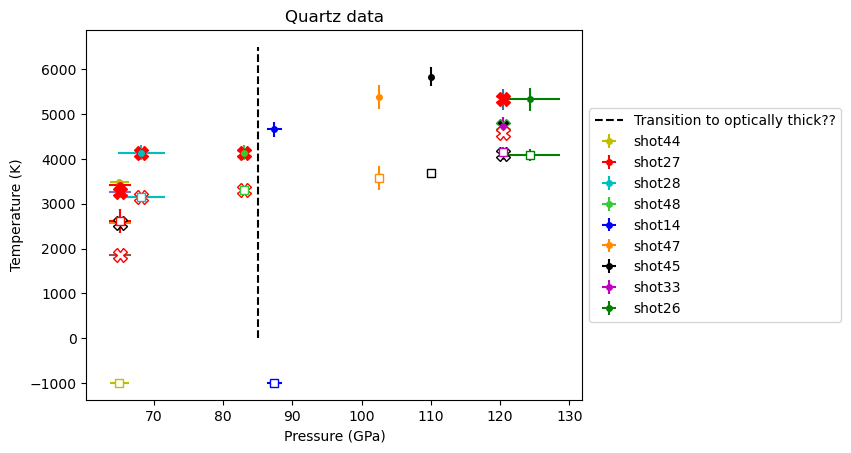

In [16]:

# Compare streak fits first

colarr = ['b','g','r','c','m','y','k','darkorange','limegreen','grey','darkviolet']
print('Shot#, Pressure (GPa), T_shock (K), T_source, Vi (km/s), Vi_err (km/s), Us (km/s), Us_err (km/s)')

isort = np.argsort(qtz_p_list)

for i in isort:
    #print(i,qtz_list[i].streak_flag[0])
    if qtz_list[i].streak_flag[0]:
        rind = np.where(ka_redo_ref == qtz_list[i].ref[0])[0]
        #print(rind)
        if len(rind) > 0:
            oneshot = ka_redo[rind[0]]
            T=np.mean(oneshot.loc[:,'fit_T_MC'])
            T_err=np.mean(oneshot.loc[:,'fit_T_MC_error'])
            T_rel=np.mean(oneshot.loc[:,'fit_T_MC_R'])
            T_rel_err=np.mean(oneshot.loc[:,'fit_T_MC_R_error'])
            print('streak comp: ',qtz_list[i].ref[0],T,T_err,T_rel,T_rel_err)
            plt.errorbar(qtz_list[i].P[0],oneshot.loc[:,'fit_T_MC'][0],xerr=qtz_list[i].P_std[0],yerr=oneshot.loc[:,'fit_T_MC_error'][0],fmt='X',markersize=10,mfc='k')
            plt.errorbar(qtz_list[i].P[0],T_rel,xerr=qtz_list[i].P_std[0],yerr=T_rel_err,fmt='X',markersize=10,mfc='white',mec='k')

for i in isort:
#    if not(qtz_list[i].streak_flag[0]):
    if 1:
        rind = np.where(ka_redo_ref == qtz_list[i].ref[0])[0]
        if len(rind) > 0:
            oneshot = ka_redo[rind[0]]
            T=np.mean(oneshot.loc[:,'fit_T_MC'])
            T_err=np.mean(oneshot.loc[:,'fit_T_MC_error'])
            T_rel=np.mean(oneshot.loc[:,'fit_T_MC_R'])
            T_rel_err=np.mean(oneshot.loc[:,'fit_T_MC_R_error'])
            if  1:
                T=np.mean(oneshot.loc[:,'extract_T'][[3]])
                T_err=np.mean(oneshot.loc[:,'extract_T_er'][[3]])
                #T_rel=np.mean(oneshot.loc[:,'Tmean_release'][[3]])
                #T_rel_err=np.mean(oneshot.loc[:,'Tmean_release_er'][[3]])
                T_rel=oneshot.loc[:,'release_Tr'][[3]]
                T_rel_err=oneshot.loc[:,'release_Tr_er'][[3]]
                
            print('NIR comp: ',qtz_list[i].ref[0],T,T_err,T_rel,T_rel_err)
            plt.errorbar(qtz_list[i].P[0],T,xerr=qtz_list[i].P_std[0],yerr=T_err,fmt='X',markersize=10,mfc='r',mec='r')
            plt.errorbar(qtz_list[i].P[0],T_rel,xerr=qtz_list[i].P_std[0],yerr=T_rel_err,fmt='X',markersize=10,mfc='white',mec='r')
            #plt.errorbar(qtz_list[i].P[0],qtz_list[i].T_rel[0],xerr=qtz_list[i].P_std[0],yerr=qtz_list[i].T_rel_std[0],fmt='s',mfc='white',markersize=6,ecolor=colarr[i],mec=colarr[i])

for i in isort:
    plt.errorbar(qtz_list[i].P[0],qtz_list[i].T[0],xerr=qtz_list[i].P_std[0],yerr=qtz_list[i].T_std[0],fmt='o',markersize=4,ecolor=colarr[i],mec=colarr[i],mfc=colarr[i],label=qtz_list[i].ref[0])
    plt.errorbar(qtz_list[i].P[0],qtz_list[i].T_rel[0],xerr=qtz_list[i].P_std[0],yerr=qtz_list[i].T_rel_std[0],fmt='s',mfc='white',markersize=6,ecolor=colarr[i],mec=colarr[i])
    print(qtz_list[i].ref[0],qtz_list[i].P[0],qtz_list[i].T[0],qtz_list[i].rem,qtz_list[i].uflyer[0],qtz_list[i].uflyer_std[0],qtz_list[i].us[0],qtz_list[i].us_std[0],qtz_list[i].streak_flag)

plt.plot([85,85],[0,6500],'k--',label='Transition to optically thick??')
plt.xlabel('Pressure (GPa)')
plt.ylabel('Temperature (K)')
plt.title('Quartz data')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5),fontsize=10)
plt.show()


Shot#, Pressure (GPa), T_shock (K), T_source, Vi (km/s), Vi_err (km/s), Us (km/s), Us_err (km/s)
streak comp:  shot27 3412.766828 91.982392 2568.939585 132.078856
streak comp:  shot33 4729.72652 205.452965 4118.465343 144.829828
shot27
NIR comp:  shot27 3263.832281 122.740921 1857.671301 2.472874
shot28
NIR comp:  shot28 4142.510301 169.457238 3160.742536 2.160646
shot48
NIR comp:  shot48 4136.765735 169.151493 3306.557492 2.583736
shot33
NIR comp:  shot33 5335.669233 234.618127 4572.998027 1.51388
shot26 124.32252836116284 5329.4 [] 6.773 0.096 9.888 0.409 [np.int64(1)]


<>:75: SyntaxWarning: invalid escape sequence '\l'
<>:75: SyntaxWarning: invalid escape sequence '\l'
/var/folders/4z/xws_ywgj78sc494vpwymn9bw0000gn/T/ipykernel_24715/1960572815.py:75: SyntaxWarning: invalid escape sequence '\l'
  plt.title('Qtz by $\lambda$: X=SOP b 1.8 g 2.3 y 3.5 r 4.8 μm')


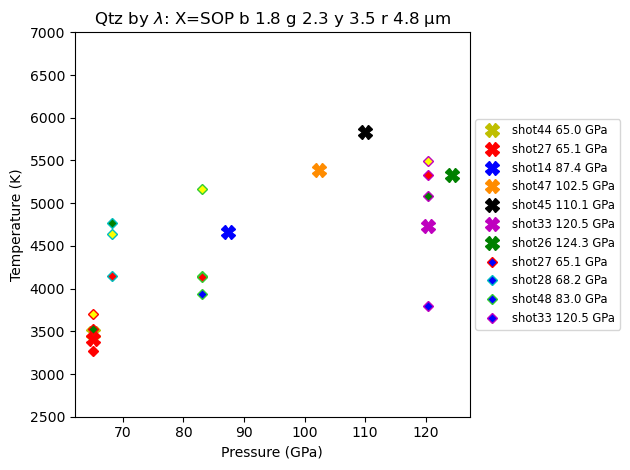

In [17]:

# Compare streak fits first

colarr = ['b','g','r','c','m','y','k','darkorange','limegreen','grey','darkviolet']
print('Shot#, Pressure (GPa), T_shock (K), T_source, Vi (km/s), Vi_err (km/s), Us (km/s), Us_err (km/s)')

isort = np.argsort(qtz_p_list)

for i in isort:
    #print(i,qtz_list[i].streak_flag[0])
    if qtz_list[i].streak_flag[0]:
        rind = np.where(ka_redo_ref == qtz_list[i].ref[0])[0]
        #print(rind)
        if len(rind) > 0:
            oneshot = ka_redo[rind[0]]
            T=np.mean(oneshot.loc[:,'fit_T_MC'])
            T_err=np.mean(oneshot.loc[:,'fit_T_MC_error'])
            T_rel=np.mean(oneshot.loc[:,'fit_T_MC_R'])
            T_rel_err=np.mean(oneshot.loc[:,'fit_T_MC_R_error'])
            print('streak comp: ',qtz_list[i].ref[0],T,T_err,T_rel,T_rel_err)
            #plt.errorbar(qtz_list[i].P[0],oneshot.loc[:,'fit_T_MC'][0],xerr=qtz_list[i].P_std[0],yerr=oneshot.loc[:,'fit_T_MC_error'][0],fmt='X',markersize=10,mfc='k')
            #plt.errorbar(qtz_list[i].P[0],T_rel,xerr=qtz_list[i].P_std[0],yerr=T_rel_err,fmt='X',markersize=10,mfc='white',mec='k')

for i in isort:
#    if not(qtz_list[i].streak_flag[0]):
    if 1:
        rind = np.where(ka_redo_ref == qtz_list[i].ref[0])[0]
        if len(rind) > 0:
            print(ka_redo_ref[rind[0]])
            oneshot = ka_redo[rind[0]]
            T=np.mean(oneshot.loc[:,'fit_T_MC'])
            T_err=np.mean(oneshot.loc[:,'fit_T_MC_error'])
            T_rel=np.mean(oneshot.loc[:,'fit_T_MC_R'])
            T_rel_err=np.mean(oneshot.loc[:,'fit_T_MC_R_error'])
            if  (qtz_list[i].ref[0]=='shot48'):
                T=np.mean(oneshot.loc[:,'extract_T'][[3]])
                T_err=np.mean(oneshot.loc[:,'extract_T_er'][[3]])
                #T_rel=np.mean(oneshot.loc[:,'Tmean_release'][[0,1,3]])
                #T_rel_err=np.mean(oneshot.loc[:,'Tmean_release_er'][[0,1,3]])            
                T_rel=np.mean(oneshot.loc[:,'release_Tr'][[0,1,3]])
                T_rel_err=np.mean(oneshot.loc[:,'release_Tr_er'][[0,1,3]])            
            #if  (qtz_list[i].ref[0]=='shot28'):
            if  1:
                T=np.mean(oneshot.loc[:,'extract_T'][[3]])
                T_err=np.mean(oneshot.loc[:,'extract_T_er'][[3]])
                #T_rel=np.mean(oneshot.loc[:,'Tmean_release'][[3]])
                #T_rel_err=np.mean(oneshot.loc[:,'Tmean_release_er'][[3]])            
                T_rel=np.mean(oneshot.loc[:,'release_Tr'][[3]])
                T_rel_err=np.mean(oneshot.loc[:,'release_Tr_er'][[3]])
            print('NIR comp: ',qtz_list[i].ref[0],T,T_err,T_rel,T_rel_err)
            #plt.errorbar(qtz_list[i].P[0],T,xerr=qtz_list[i].P_std[0],yerr=T_err,fmt='X',markersize=10,mfc='r',mec='r')
            #plt.errorbar(qtz_list[i].P[0],T_rel,xerr=qtz_list[i].P_std[0],yerr=T_rel_err,fmt='X',markersize=10,mfc='white',mec='r')
            #plt.errorbar(qtz_list[i].P[0],qtz_list[i].T_rel[0],xerr=qtz_list[i].P_std[0],yerr=qtz_list[i].T_rel_std[0],fmt='s',mfc='white',markersize=6,ecolor=colarr[i],mec=colarr[i])
            plt.errorbar(qtz_list[i].P[0],oneshot.loc[:,'extract_T'][[0]],fmt='D',markersize=5,mfc='b',mec=colarr[i],label=qtz_list[i].ref[0]+' '+str(np.round(qtz_list[i].P[0]*10.)/10)+' GPa')
            plt.errorbar(qtz_list[i].P[0],oneshot.loc[:,'extract_T'][[1]],fmt='D',markersize=5,mfc='g',mec=colarr[i])
            plt.errorbar(qtz_list[i].P[0],oneshot.loc[:,'extract_T'][[2]],fmt='D',markersize=5,mfc='yellow',mec=colarr[i])
            plt.errorbar(qtz_list[i].P[0],oneshot.loc[:,'extract_T'][[3]],fmt='D',markersize=5,mfc='r',mec=colarr[i])

for i in isort:
    if (qtz_list[i].ref[0] != 'shot28') and (qtz_list[i].ref[0] != 'shot48'):
        plt.plot(qtz_list[i].P,qtz_list[i].T,'X',markersize=10,color=colarr[i],label=qtz_list[i].ref[0]+' '+str(np.round(qtz_list[i].P[0]*10.)/10)+' GPa')
    #plt.errorbar(qtz_list[i].P[0],qtz_list[i].T_rel[0],xerr=qtz_list[i].P_std[0],yerr=qtz_list[i].T_rel_std[0],fmt='s',mfc='white',markersize=6,ecolor=colarr[i],mec=colarr[i])
print(qtz_list[i].ref[0],qtz_list[i].P[0],qtz_list[i].T[0],qtz_list[i].rem,qtz_list[i].uflyer[0],qtz_list[i].uflyer_std[0],qtz_list[i].us[0],qtz_list[i].us_std[0],qtz_list[i].streak_flag)

if 0:
    plt.errorbar(shockdat_list[B88qtz['id']].P,shockdat_list[B88qtz['id']].T,fmt='go-',mfc='white',yerr=shockdat_list[B88qtz['id']].T_std,label=B88qtz['lab'])
    plt.errorbar(shockdat_list[B88qtz['id']].P,shockdat_list[B88qtz['id']].T,fmt='go',mfc='white',yerr=shockdat_list[B88qtz['id']].T_std,label=B88qtz['lab']+'(no imp info)')
    ind = np.where(shockdat_list[B88Rqtz['id']].us>0)
    plt.errorbar(shockdat_list[B88Rqtz['id']].P[ind],shockdat_list[B88Rqtz['id']].T[ind],fmt='go',mfc='yellow',\
                     yerr=shockdat_list[B88Rqtz['id']].T_std[ind],label=B88Rqtz['lab']+'(z)')
                #ind = np.where(shockdat_list[B88Rqtz['id']].orientation == 'pz')[0]

plt.xlabel('Pressure (GPa)')
plt.ylabel('Temperature (K)')
plt.ylim(2500,7000)
plt.title('Qtz by $\lambda$: X=SOP b 1.8 g 2.3 y 3.5 r 4.8 μm')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5),fontsize='small')
plt.tight_layout()
plt.savefig('../output-figs/UCD-QTZ-wavelength.pdf')


## Fused silica

Shot#, Pressure (GPa), T_shock (K), T_source, Vi (km/s), Vi_err (km/s), Us (km/s), Us_err (km/s)
Shot#, Pressure (GPa), T_shock (K), T_source, Vi (km/s), Vi_err (km/s), Us (km/s), Us_err (km/s)
streak comp:  shot22 6399.8308609999995 205.788279 4163.454368 122.252146
NIR comp:  shot41 4670.915207 215.473432 3029.1886 394.234844
NIR comp:  shot23 4200.175571 166.824686 4143.084441 73.35743
NIR comp:  shot31 4611.090845 188.372861 4400.473535 242.983568
NIR comp:  shot25 4483.578691 144.012047 3420.640936 0.139423
NIR comp:  shot20 5027.312258 199.316536 4859.953284 114.437458
NIR comp:  shot22 4573.230527 186.392369 4036.057662 178.437877
NIR comp:  shot21 6703.3406365 284.2545605 4455.373226 27.24451
shot41 54.32443426562305 4670.915 [] 4.687 0.003 6.8343 0.112 [np.int64(0)]
shot40 56.528901686378255 -999.0 [] 4.766 0.003 7.007 0.353 [np.int64(0)]
shot50 68.06379203710938 5170.0 [] 5.353 0.004 7.62 0.0 [np.int64(1)]
shot23 82.90944976418177 4200.1755 [] 5.916 0.08 8.579 0.131 [np.int64

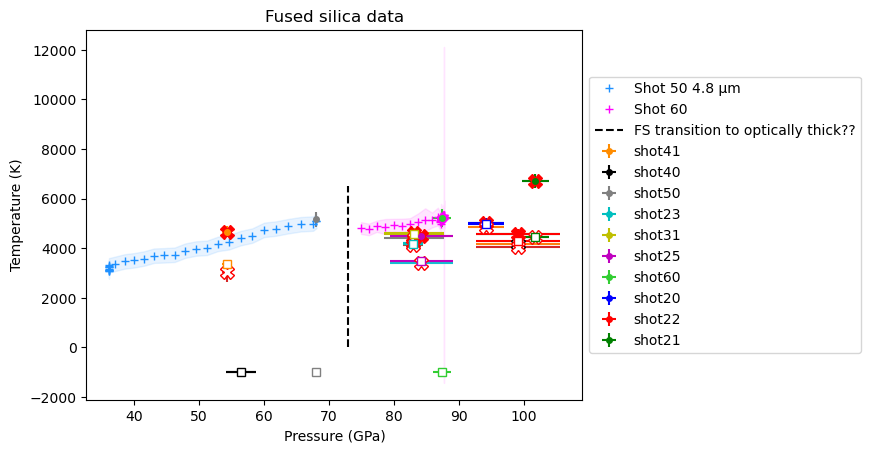

In [18]:

colarr = ['b','g','r','c','m','y','k','darkorange','limegreen','grey','darkviolet']
isort = np.argsort(fs_p_list)
print('Shot#, Pressure (GPa), T_shock (K), T_source, Vi (km/s), Vi_err (km/s), Us (km/s), Us_err (km/s)')

# Compare streak fits first

colarr = ['b','g','r','c','m','y','k','darkorange','limegreen','grey','darkviolet']
print('Shot#, Pressure (GPa), T_shock (K), T_source, Vi (km/s), Vi_err (km/s), Us (km/s), Us_err (km/s)')

isort = np.argsort(fs_p_list)

for i in isort:
    #print(i,fs_list[i].streak_flag[0])
    if fs_list[i].streak_flag[0]:
        rind = np.where(ka_redo_ref == fs_list[i].ref[0])[0]
        #print(rind)
        if len(rind) > 0:
            oneshot = ka_redo[rind[0]]
            T=np.mean(oneshot.loc[:,'fit_T_MC'])
            T_err=np.mean(oneshot.loc[:,'fit_T_MC_error'])
            T_rel=np.mean(oneshot.loc[:,'fit_T_MC_R'])
            T_rel_err=np.mean(oneshot.loc[:,'fit_T_MC_R_error'])
            print('streak comp: ',fs_list[i].ref[0],T,T_err,T_rel,T_rel_err)
            plt.errorbar(fs_list[i].P[0],oneshot.loc[:,'fit_T_MC'][0],xerr=fs_list[i].P_std[0],yerr=oneshot.loc[:,'fit_T_MC_error'][0],fmt='X',markersize=10,mfc='k')
            plt.errorbar(fs_list[i].P[0],T_rel,xerr=fs_list[i].P_std[0],yerr=T_rel_err,fmt='X',markersize=10,mfc='white',mec='k')

for i in isort:
#    if not(fs_list[i].streak_flag[0]):
    if 1:
        rind = np.where(ka_redo_ref == fs_list[i].ref[0])[0]
        if len(rind) > 0:
            oneshot = ka_redo[rind[0]]
            T=np.mean(oneshot.loc[:,'fit_T_MC'])
            T_err=np.mean(oneshot.loc[:,'fit_T_MC_error'])
            T_rel=np.mean(oneshot.loc[:,'fit_T_MC_R'])
            T_rel_err=np.mean(oneshot.loc[:,'fit_T_MC_R_error'])
            if  (fs_list[i].ref[0]=='shot21'):# or (fs_list[i].ref[0]=='shot20'):# or (fs_list[i].ref[0]=='shot23'):#  or (fs_list[i].ref[0]=='shot31'):
                T=np.mean(oneshot.loc[:,'extract_T'][[1,2]])
                T_err=np.mean(oneshot.loc[:,'extract_T_er'][[1,2]])
                T_rel=np.mean(oneshot.loc[:,'Tmean_release'][[1,2]])
                T_rel_err=np.mean(oneshot.loc[:,'Tmean_release_er'][[1,2]])            
            if  (fs_list[i].ref[0]=='shot25'):
                T=np.mean(oneshot.loc[:,'extract_T'][[1]])
                T_err=np.mean(oneshot.loc[:,'extract_T_er'][[1]])
                T_rel=np.mean(oneshot.loc[:,'fit_T_MC_R'][[1]])
                T_rel_err=np.mean(oneshot.loc[:,'fit_T_MC_R_error'][[1]])           
            if  (fs_list[i].ref[0]!='shot21') and  (fs_list[i].ref[0]!='shot25'):# and  (fs_list[i].ref[0]!='shot20'):# and  (fs_list[i].ref[0]!='shot31'):
#            if 1:
                T=np.mean(oneshot.loc[:,'extract_T'][[3]])
                T_err=np.mean(oneshot.loc[:,'extract_T_er'][[3]])
                T_rel=np.mean(oneshot.loc[:,'Tmean_release'][[3]])
                T_rel_err=np.mean(oneshot.loc[:,'Tmean_release_er'][[3]])            
            print('NIR comp: ',fs_list[i].ref[0],T,T_err,T_rel,T_rel_err)
            plt.errorbar(fs_list[i].P[0],T,xerr=fs_list[i].P_std[0],yerr=T_err,fmt='X',markersize=10,mfc='r',mec='r')
            plt.errorbar(fs_list[i].P[0],T_rel,xerr=fs_list[i].P_std[0],yerr=T_rel_err,fmt='X',markersize=10,mfc='white',mec='r')
            #plt.errorbar(fs_list[i].P[0],fs_list[i].T_rel[0],xerr=fs_list[i].P_std[0],yerr=fs_list[i].T_rel_std[0],fmt='s',mfc='white',markersize=6,ecolor=colarr[i],mec=colarr[i])

for i in isort:
    plt.errorbar(fs_list[i].P[0],fs_list[i].T[0],xerr=fs_list[i].P_std[0],yerr=fs_list[i].T_std[0],fmt='o',markersize=4,ecolor=colarr[i],mec=colarr[i],mfc=colarr[i],label=fs_list[i].ref[0])
    plt.errorbar(fs_list[i].P[0],fs_list[i].T_rel[0],xerr=fs_list[i].P_std[0],yerr=fs_list[i].T_rel_std[0],fmt='s',mfc='white',markersize=6,ecolor=colarr[i],mec=colarr[i])
    print(fs_list[i].ref[0],fs_list[i].P[0],fs_list[i].T[0],fs_list[i].rem,fs_list[i].uflyer[0],fs_list[i].uflyer_std[0],fs_list[i].us[0],fs_list[i].us_std[0],fs_list[i].streak_flag)


plt.plot(s50pres[ind50[40::]],s50tempbackout[ind50[40::]],'+',color='dodgerblue',label='Shot 50 4.8 μm')
plt.fill_between(s50pres[ind50[40::]],s50tempbackout[ind50[40::]]-Tsteady_err,s50tempbackout[ind50[40::]]+Tsteady_err, color='dodgerblue', alpha = 0.1)

plt.plot(s60pres[ind60],s60temp[ind60],'+',color='magenta',label='Shot 60')
plt.fill_between(s60pres[ind60[isort60]],s60temp[ind60[isort60]]-s60temperr[ind60[isort60]],s60temp[ind60[isort60]]+s60temperr[ind60[isort60]], color='magenta', alpha = 0.1)

plt.plot([73,73],[0,6500],'k--',label='FS transition to optically thick??')
plt.xlabel('Pressure (GPa)')
plt.ylabel('Temperature (K)')
plt.title('Fused silica data')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5),fontsize=10)
plt.show()


Shot#, Pressure (GPa), T_shock (K), T_source, Vi (km/s), Vi_err (km/s), Us (km/s), Us_err (km/s)
Shot#, Pressure (GPa), T_shock (K), T_source, Vi (km/s), Vi_err (km/s), Us (km/s), Us_err (km/s)
streak comp:  shot22 6399.8308609999995 205.788279 4163.454368 122.252146
NIR comp:  shot41 4670.915207 215.473432 3029.1886 394.234844
NIR comp:  shot23 4200.175571 166.824686 4143.084441 73.35743
NIR comp:  shot31 4611.090845 188.372861 4400.473535 242.983568
NIR comp:  shot25 4483.578691 144.012047 3420.640936 0.139423
NIR comp:  shot20 5027.312258 199.316536 4859.953284 114.437458
NIR comp:  shot22 4573.230527 186.392369 4036.057662 178.437877
NIR comp:  shot21 6703.3406365 284.2545605 4455.373226 27.24451
shot41 54.32443426562305 4670.915 [] 4.687 0.003 6.8343 0.112 [np.int64(0)]
shot40 56.528901686378255 -999.0 [] 4.766 0.003 7.007 0.353 [np.int64(0)]
shot50 68.06379203710938 5170.0 [] 5.353 0.004 7.62 0.0 [np.int64(1)]
shot23 82.90944976418177 4200.1755 [] 5.916 0.08 8.579 0.131 [np.int64

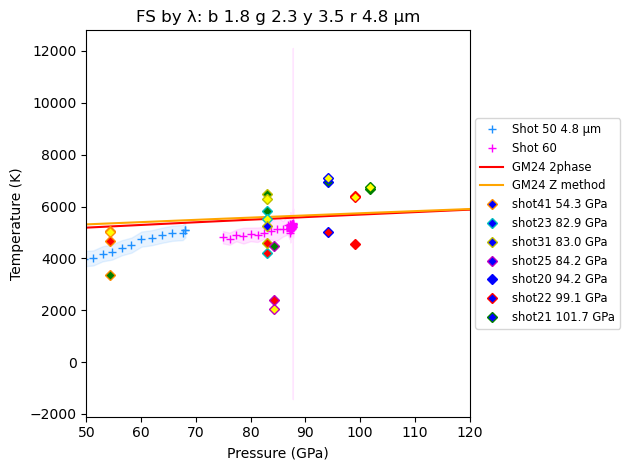

In [19]:
## Plot each wavelength end temperature

colarr = ['b','g','r','c','m','y','k','darkorange','limegreen','grey','darkviolet']
isort = np.argsort(fs_p_list)
print('Shot#, Pressure (GPa), T_shock (K), T_source, Vi (km/s), Vi_err (km/s), Us (km/s), Us_err (km/s)')

# Compare streak fits first

colarr = ['b','g','r','c','m','y','k','darkorange','limegreen','grey','darkviolet']
print('Shot#, Pressure (GPa), T_shock (K), T_source, Vi (km/s), Vi_err (km/s), Us (km/s), Us_err (km/s)')

isort = np.argsort(fs_p_list)

for i in isort:
    #print(i,fs_list[i].streak_flag[0])
    if fs_list[i].streak_flag[0]:
        rind = np.where(ka_redo_ref == fs_list[i].ref[0])[0]
        #print(rind)
        if len(rind) > 0:
            oneshot = ka_redo[rind[0]]
            T=np.mean(oneshot.loc[:,'fit_T_MC'])
            T_err=np.mean(oneshot.loc[:,'fit_T_MC_error'])
            T_rel=np.mean(oneshot.loc[:,'fit_T_MC_R'])
            T_rel_err=np.mean(oneshot.loc[:,'fit_T_MC_R_error'])
            print('streak comp: ',fs_list[i].ref[0],T,T_err,T_rel,T_rel_err)
            #plt.errorbar(fs_list[i].P[0],oneshot.loc[:,'fit_T_MC'][0],xerr=fs_list[i].P_std[0],yerr=oneshot.loc[:,'fit_T_MC_error'][0],fmt='X',markersize=10,mfc='k')
            #plt.errorbar(fs_list[i].P[0],T_rel,xerr=fs_list[i].P_std[0],yerr=T_rel_err,fmt='X',markersize=10,mfc='white',mec='k')
plt.plot(s50pres[ind50[40::]],s50tempbackout[ind50[40::]],'+',color='dodgerblue',label='Shot 50 4.8 μm')
plt.fill_between(s50pres[ind50[40::]],s50tempbackout[ind50[40::]]-Tsteady_err,s50tempbackout[ind50[40::]]+Tsteady_err, color='dodgerblue', alpha = 0.1)

plt.plot(s60pres[ind60],s60temp[ind60],'+',color='magenta',label='Shot 60')
plt.fill_between(s60pres[ind60[isort60]],s60temp[ind60[isort60]]-s60temperr[ind60[isort60]],s60temp[ind60[isort60]]+s60temperr[ind60[isort60]], color='magenta', alpha = 0.1)

for i in isort:
#    if not(fs_list[i].streak_flag[0]):
    if 1:
        rind = np.where(ka_redo_ref == fs_list[i].ref[0])[0]
        if len(rind) > 0:
            oneshot = ka_redo[rind[0]]
            T=np.mean(oneshot.loc[:,'fit_T_MC'])
            T_err=np.mean(oneshot.loc[:,'fit_T_MC_error'])
            T_rel=np.mean(oneshot.loc[:,'fit_T_MC_R'])
            T_rel_err=np.mean(oneshot.loc[:,'fit_T_MC_R_error'])
            if  (fs_list[i].ref[0]=='shot21'):# or (fs_list[i].ref[0]=='shot20'):# or (fs_list[i].ref[0]=='shot23'):#  or (fs_list[i].ref[0]=='shot31'):
                T=np.mean(oneshot.loc[:,'extract_T'][[1,2]])
                T_err=np.mean(oneshot.loc[:,'extract_T_er'][[1,2]])
                T_rel=np.mean(oneshot.loc[:,'Tmean_release'][[1,2]])
                T_rel_err=np.mean(oneshot.loc[:,'Tmean_release_er'][[1,2]])            
            if  (fs_list[i].ref[0]=='shot25'):
                T=np.mean(oneshot.loc[:,'extract_T'][[1]])
                T_err=np.mean(oneshot.loc[:,'extract_T_er'][[1]])
                T_rel=np.mean(oneshot.loc[:,'fit_T_MC_R'][[1]])
                T_rel_err=np.mean(oneshot.loc[:,'fit_T_MC_R_error'][[1]])           
            if  (fs_list[i].ref[0]!='shot21') and  (fs_list[i].ref[0]!='shot25'):# and  (fs_list[i].ref[0]!='shot20'):# and  (fs_list[i].ref[0]!='shot31'):
#            if 1:
                T=np.mean(oneshot.loc[:,'extract_T'][[3]])
                T_err=np.mean(oneshot.loc[:,'extract_T_er'][[3]])
                T_rel=np.mean(oneshot.loc[:,'Tmean_release'][[3]])
                T_rel_err=np.mean(oneshot.loc[:,'Tmean_release_er'][[3]])            
            print('NIR comp: ',fs_list[i].ref[0],T,T_err,T_rel,T_rel_err)
            #plt.errorbar(fs_list[i].P[0],T,xerr=fs_list[i].P_std[0],yerr=T_err,fmt='X',markersize=10,mfc='r',mec='r')
            #plt.errorbar(fs_list[i].P[0],T_rel,xerr=fs_list[i].P_std[0],yerr=T_rel_err,fmt='X',markersize=10,mfc='white',mec='r')
            #plt.errorbar(fs_list[i].P[0],fs_list[i].T_rel[0],xerr=fs_list[i].P_std[0],yerr=fs_list[i].T_rel_std[0],fmt='s',mfc='white',markersize=6,ecolor=colarr[i],mec=colarr[i])

            plt.errorbar(fs_list[i].P[0],oneshot.loc[:,'extract_T'][[0]],fmt='D',markersize=5,mfc='b',mec=colarr[i],label=fs_list[i].ref[0]+' '+str(np.round(fs_list[i].P[0]*10.)/10)+' GPa')
            plt.errorbar(fs_list[i].P[0],oneshot.loc[:,'extract_T'][[1]],fmt='D',markersize=5,mfc='g',mec=colarr[i])
            plt.errorbar(fs_list[i].P[0],oneshot.loc[:,'extract_T'][[2]],fmt='D',markersize=5,mfc='yellow',mec=colarr[i])
            plt.errorbar(fs_list[i].P[0],oneshot.loc[:,'extract_T'][[3]],fmt='D',markersize=5,mfc='r',mec=colarr[i])
for i in isort:
    #plt.errorbar(fs_list[i].P[0],fs_list[i].T[0],xerr=fs_list[i].P_std[0],yerr=fs_list[i].T_std[0],fmt='o',markersize=1,ecolor=colarr[i],mec=colarr[i],mfc=colarr[i],label=fs_list[i].ref[0])
    #plt.errorbar(fs_list[i].P[0],fs_list[i].T_rel[0],xerr=fs_list[i].P_std[0],yerr=fs_list[i].T_rel_std[0],fmt='s',mfc='white',markersize=1,ecolor=colarr[i],mec=colarr[i])
    print(fs_list[i].ref[0],fs_list[i].P[0],fs_list[i].T[0],fs_list[i].rem,fs_list[i].uflyer[0],fs_list[i].uflyer_std[0],fs_list[i].us[0],fs_list[i].us_std[0],fs_list[i].streak_flag)

if 0:
    plt.errorbar(shockdat_list[B88fs['id']].P,shockdat_list[B88fs['id']].T,fmt='bo',mfc='white',yerr=shockdat_list[B88fs['id']].T_std,label=B88fs['lab'])
    ind = np.where(shockdat_list[B88Rfs['id']].T>0)
    plt.errorbar(shockdat_list[B88Rfs['id']].P[ind],shockdat_list[B88Rfs['id']].T[ind],fmt='bo',mfc='lightblue',yerr=shockdat_list[B88Rfs['id']].T_std[ind],label=B88Rfs['lab'])

    plt.errorbar(shockdat_list[S80fs['id']].P,shockdat_list[S80fs['id']].T,fmt='bv',xerr=shockdat_list[S80fs['id']].P_std,yerr=shockdat_list[S80fs['id']].T_std,label=S80fs['lab'])
    plt.errorbar(shockdat_list[S81fs['id']].P,shockdat_list[S81fs['id']].T,fmt='bx',label=S81fs['lab'])

    #for i in range(len(fs_good_list)):
    #    plt.plot(fs_good_list[i].P,fs_good_list[i].T,'D',mfc='yellow',mec='k')
    plt.xlim(20,120)
    plt.ylim(2500,8000)

if 1:
        
    #plot fit to Geng and Mohn 2024
    pg24arr = np.arange(500)+50 # GPa
    tg24arr = 6.018*np.power((1+(pg24arr+202.338)/4.736e-04),0.5126)
    plt.plot(pg24arr,tg24arr,'r-',label='GM24 2phase')
    pg24arr = np.arange(500)+50 # GPa
    tg24arr = 6.426*np.power((1+(pg24arr+256.011)/6.474e-04),0.5141)
    plt.plot(pg24arr,tg24arr,'-',color='orange',label='GM24 Z method')

#plt.plot([73,73],[0,6500],'k--',label='FS transition to optically thick??')
plt.xlabel('Pressure (GPa)')
plt.ylabel('Temperature (K)')
plt.xlim(50,120)
plt.title('FS by λ: b 1.8 g 2.3 y 3.5 r 4.8 μm')
plt.legend(loc='center left', bbox_to_anchor=(1., 0.5),fontsize='small')
plt.tight_layout()
plt.savefig('../output-figs/UCD-FS-wavelength.pdf')
plt.show()



Shot#, Pressure (GPa), T_shock (K), T_source, Vi (km/s), Vi_err (km/s), Us (km/s), Us_err (km/s)
shot44 65.00989408020008 3480.0 [] 4.578 0.003 7.401 0.215
shot27 65.10390400961398 3412.766828 [] 4.569 0.101 7.43 0.052
shot28 68.21054891984602 4142.510301 [] 4.705 0.2 7.553 0.23
shot48 82.99306752903478 4136.765735 [] 5.278 0.004 8.2994 0.0042
shot14 87.43147985491223 4661.0 [] 5.467 0.062 8.46 0.015
shot47 102.45349705917714 5384.0 [] 6.038 0.005 9.032 0.046
shot45 110.05003371145129 5837.0 [] 6.301 0.005 9.317 0.0111
shot33 120.45097265412994 4729.72652 [] 6.665 0.004 9.741 0.033
shot26 124.32252836116284 5329.4 [] 6.773 0.096 9.888 0.409


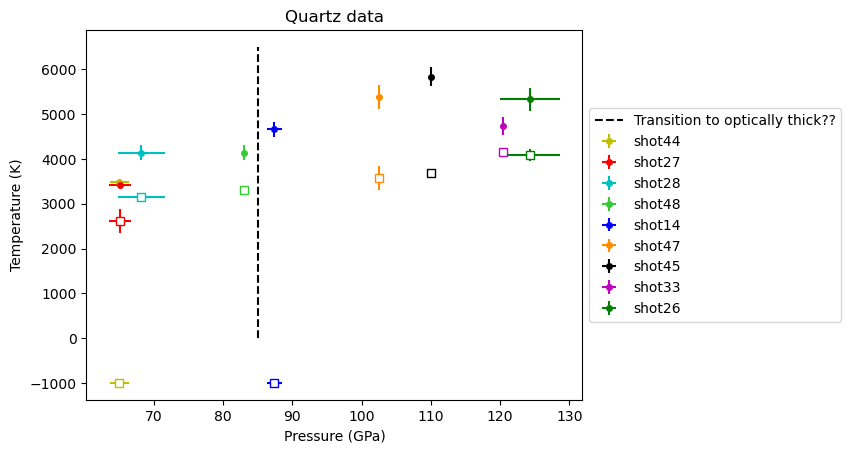

Shot#, rho (g/cm3), rho_err (g/cm34)
shot44 4.808365823462667 0.13759935767613615
shot27 4.773382354709332 0.0948829069457645
shot28 4.8463428366516865 0.23386954094301196
shot48 4.859850448829426 0.007571349686829736
shot14 4.916686588509419 0.05386219439000621
shot47 5.035823207343356 0.028899264467072087
shot45 5.081662952940684 0.009169851303460722
shot33 5.084388548548154 0.020708653009908613
shot26 5.101509280306507 0.26502636285415526


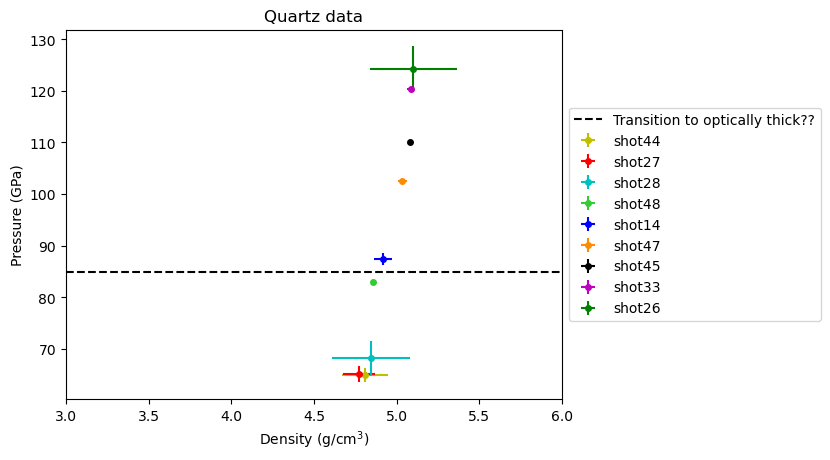

Shot#, rho (g/cm3), rho_err (g/cm34)
shot44 4.808365823462667 0.13759935767613615
shot27 4.773382354709332 0.0948829069457645
shot28 4.8463428366516865 0.23386954094301196
shot48 4.859850448829426 0.007571349686829736
shot14 4.916686588509419 0.05386219439000621
shot47 5.035823207343356 0.028899264467072087
shot45 5.081662952940684 0.009169851303460722
shot33 5.084388548548154 0.020708653009908613
shot26 5.101509280306507 0.26502636285415526


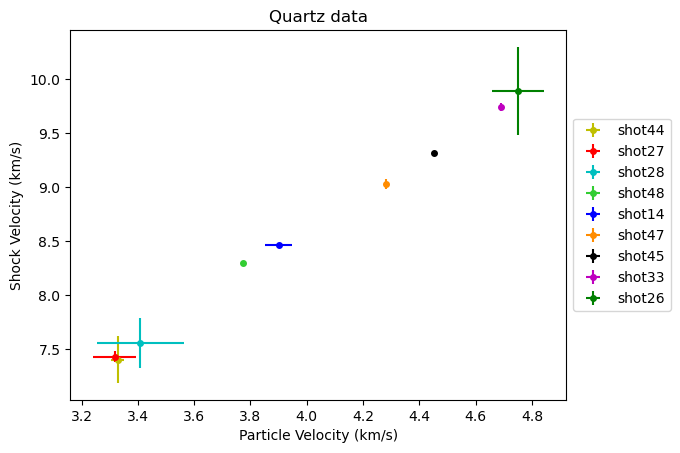

 
Notes: 
Shot 44 density is too dense because not taking into account 2 wave structure; will try to fix.
Shots 44 and 27 have structured wavefronts; 44 a clear 2 wave sructure. No release on 44 - off streak; plotting first wave; second wave warmer at 3577 K
Any chance of getting release temp on shot 14?
shots 28, 48 has structured release temps; did shot 14 have NIR profiles to check even if no calibration?
shot 28 is suspiciously dense; like we are missing a 2-wave structure.
Shot 32 will improve when PDV is analyzed; did it have structured release?
Shot 47 no IR?
Shot 45 clean release profile; I do not have the IR temperature fits for IR 1-4
Shot 26 unfortuante error bars; need another good point after the dip between 120-135 GPa


In [20]:
colarr = ['b','g','r','c','m','y','k','darkorange','limegreen','grey','darkviolet']
print('Shot#, Pressure (GPa), T_shock (K), T_source, Vi (km/s), Vi_err (km/s), Us (km/s), Us_err (km/s)')

isort = np.argsort(qtz_p_list)
for i in isort:
    plt.errorbar(qtz_list[i].P[0],qtz_list[i].T[0],xerr=qtz_list[i].P_std[0],yerr=qtz_list[i].T_std[0],fmt='o',markersize=4,ecolor=colarr[i],mec=colarr[i],mfc=colarr[i],label=qtz_list[i].ref[0])
    plt.errorbar(qtz_list[i].P[0],qtz_list[i].T_rel[0],xerr=qtz_list[i].P_std[0],yerr=qtz_list[i].T_rel_std[0],fmt='s',mfc='white',markersize=6,ecolor=colarr[i],mec=colarr[i])
    print(qtz_list[i].ref[0],qtz_list[i].P[0],qtz_list[i].T[0],qtz_list[i].rem,qtz_list[i].uflyer[0],qtz_list[i].uflyer_std[0],qtz_list[i].us[0],qtz_list[i].us_std[0])
plt.plot([85,85],[0,6500],'k--',label='Transition to optically thick??')
plt.xlabel('Pressure (GPa)')
plt.ylabel('Temperature (K)')
plt.title('Quartz data')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5),fontsize=10)
plt.show()

print('Shot#, rho (g/cm3), rho_err (g/cm34)')
for i in isort:
    plt.errorbar(qtz_list[i].rho[0],qtz_list[i].P[0],xerr=qtz_list[i].rho_std[0],yerr=qtz_list[i].P_std[0],fmt='o',markersize=4,ecolor=colarr[i],mec=colarr[i],mfc=colarr[i],label=qtz_list[i].ref[0])
    print(qtz_list[i].ref[0],qtz_list[i].rho[0],qtz_list[i].rho_std[0])
#plt.plot([73,73],[0,6500],'k--',label='Transition to optically thick??')
plt.ylabel('Pressure (GPa)')
plt.xlabel('Density (g/cm$^3$)')
plt.xlim(3,6)
plt.plot([3,6],[85,85],'k--',label='Transition to optically thick??')
plt.title('Quartz data')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5),fontsize=10)
plt.show()

print('Shot#, rho (g/cm3), rho_err (g/cm34)')
for i in isort:
    plt.errorbar(qtz_list[i].up[0],qtz_list[i].us[0],xerr=qtz_list[i].up_std[0],yerr=qtz_list[i].us_std[0],fmt='o',markersize=4,ecolor=colarr[i],mec=colarr[i],mfc=colarr[i],label=qtz_list[i].ref[0])
    print(qtz_list[i].ref[0],qtz_list[i].rho[0],qtz_list[i].rho_std[0])
#plt.plot([73,73],[0,6500],'k--',label='Transition to optically thick??')
plt.xlabel('Particle Velocity (km/s)')
plt.ylabel('Shock Velocity (km/s)')
#plt.xlim(3,6)
#plt.plot([3,6],[85,85],'k--',label='Transition to optically thick??')
plt.title('Quartz data')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5),fontsize=10)
plt.show()


print(' ')
print('Notes: ')
print('Shot 44 density is too dense because not taking into account 2 wave structure; will try to fix.')
print('Shots 44 and 27 have structured wavefronts; 44 a clear 2 wave sructure. No release on 44 - off streak; plotting first wave; second wave warmer at 3577 K')
print('Any chance of getting release temp on shot 14?')
print('shots 28, 48 has structured release temps; did shot 14 have NIR profiles to check even if no calibration?')
print('shot 28 is suspiciously dense; like we are missing a 2-wave structure.')
print('Shot 32 will improve when PDV is analyzed; did it have structured release?')
print('Shot 47 no IR?')
print('Shot 45 clean release profile; I do not have the IR temperature fits for IR 1-4')
print('Shot 26 unfortuante error bars; need another good point after the dip between 120-135 GPa')


Shot#, Pressure (GPa), T_shock (K), T_source, Vi (km/s), Vi_err (km/s), Us (km/s), Us_err (km/s)
shot41 54.32443426562305 4670.915 [] 4.687 0.003 6.8343 0.112
shot40 56.528901686378255 -999.0 [] 4.766 0.003 7.007 0.353
shot50 68.06379203710938 5170.0 [] 5.353 0.004 7.62 0.0
shot23 82.90944976418177 4200.1755 [] 5.916 0.08 8.579 0.131
shot31 83.03434421043941 4611.0908 [] 5.878 0.294 8.569 0.025
shot25 84.17608214986328 4483.578691 [] 6.003 0.274 8.544 0.35
shot60 87.37011891423583 5239.0 [] 6.142 0.09 8.6425 0.03264
shot20 94.18660988337355 5027.3122 [] 6.386 0.133 9.144 0.212
shot22 99.09285426949843 4573.230527 [] 6.67 0.35 9.163 0.363
shot21 101.74287645992194 6703.340637 [] 6.718 0.075 9.308 0.199


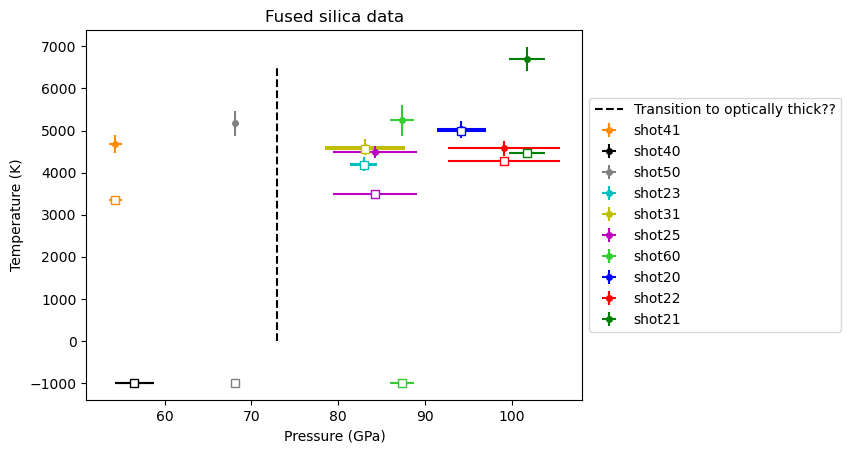

Shot#, rho (g/cm3), rho_err (g/cm34)
shot41 4.67466593240612 0.10601134883891947
shot40 4.648752266998038 0.3285511940132734
shot50 4.708101471797891 0.0
shot23 4.519863177975142 0.11784925151513982
shot31 4.543656542135098 0.2694541438279699
shot25 4.662315098964336 0.3885229385539648
shot60 4.701540560792448 0.08824641101363272
shot20 4.51875186136032 0.1852987412911018
shot22 4.811528028352889 0.4502558064394971
shot21 4.737628065576169 0.16081779349644232


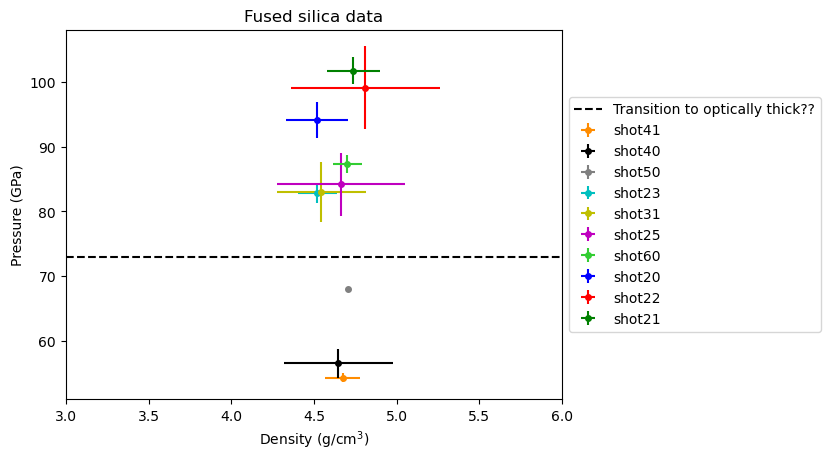

Shot#, rho (g/cm3), rho_err (g/cm34)
shot41 4.67466593240612 0.10601134883891947 54.32443426562305
shot40 4.648752266998038 0.3285511940132734 56.528901686378255
shot50 4.708101471797891 0.0 68.06379203710938
shot23 4.519863177975142 0.11784925151513982 82.90944976418177
shot31 4.543656542135098 0.2694541438279699 83.03434421043941
shot25 4.662315098964336 0.3885229385539648 84.17608214986328
shot60 4.701540560792448 0.08824641101363272 87.37011891423583
shot20 4.51875186136032 0.1852987412911018 94.18660988337355
shot22 4.811528028352889 0.4502558064394971 99.09285426949843
shot21 4.737628065576169 0.16081779349644232 101.74287645992194


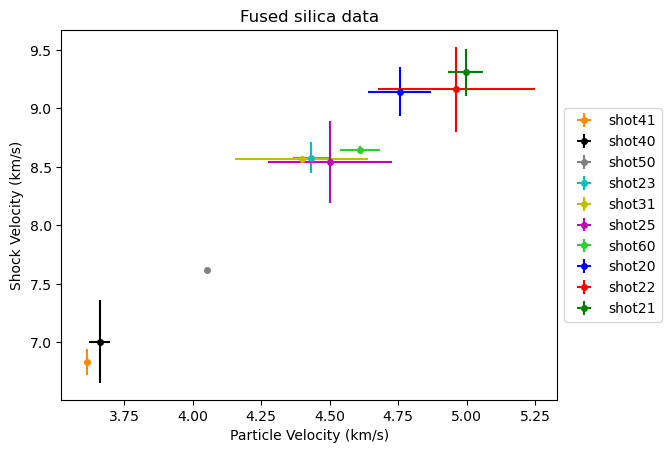

 
Notes: 
Shot 22 has bad blow by and no impact velocity; plot on the fitted Hugoniot for shock-and-release observations. Will be near Shot 20.
Shot 41 has structured release.
Shot 40 has probe contamination; no real temps; use for PV Hugoniot plots (big error bar point though)
Shot 31 and 25 have clean release
Shot 23 needs wave profiles in Erik spreadsheet
Shot 20 weird visible channels; streak and IR seems good point.
Shot 21 had peak IR temp clips; no streak; still seems usable
Most temperatures are from Table 3.4 in thesis.
Need to look at why shots 31, 23, 25 are so close in pressure but variable in temperature! If these were <80 GPa then they would be within the melt curve, but if just above the melt curve, strange variability.


In [21]:
colarr = ['b','g','r','c','m','y','k','darkorange','limegreen','grey','darkviolet']
isort = np.argsort(fs_p_list)
print('Shot#, Pressure (GPa), T_shock (K), T_source, Vi (km/s), Vi_err (km/s), Us (km/s), Us_err (km/s)')
for i in isort:
    plt.errorbar(fs_list[i].P[0],fs_list[i].T[0],xerr=fs_list[i].P_std[0],yerr=fs_list[i].T_std[0],fmt='o',markersize=4,ecolor=colarr[i],mec=colarr[i],mfc=colarr[i],label=fs_list[i].ref[0])
    plt.errorbar(fs_list[i].P[0],fs_list[i].T_rel[0],xerr=fs_list[i].P_std[0],yerr=fs_list[i].T_rel_std[0],fmt='s',mfc='white',markersize=6,ecolor=colarr[i],mec=colarr[i])
    print(fs_list[i].ref[0],fs_list[i].P[0],fs_list[i].T[0],fs_list[i].rem,fs_list[i].uflyer[0],fs_list[i].uflyer_std[0],fs_list[i].us[0],fs_list[i].us_std[0])
plt.plot([73,73],[0,6500],'k--',label='Transition to optically thick??')
plt.xlabel('Pressure (GPa)')
plt.ylabel('Temperature (K)')
plt.title('Fused silica data')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5),fontsize=10)
plt.show()

print('Shot#, rho (g/cm3), rho_err (g/cm34)')
for i in isort:
    plt.errorbar(fs_list[i].rho[0],fs_list[i].P[0],xerr=fs_list[i].rho_std[0],yerr=fs_list[i].P_std[0],fmt='o',markersize=4,ecolor=colarr[i],mec=colarr[i],mfc=colarr[i],label=fs_list[i].ref[0])
    print(fs_list[i].ref[0],fs_list[i].rho[0],fs_list[i].rho_std[0])
plt.ylabel('Pressure (GPa)')
plt.xlabel('Density (g/cm$^3$)')
plt.xlim(3,6)
plt.plot([3,6],[73,73],'k--',label='Transition to optically thick??')
plt.title('Fused silica data')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5),fontsize=10)
plt.show()

print('Shot#, rho (g/cm3), rho_err (g/cm34)')
for i in isort:
    plt.errorbar(fs_list[i].up[0],fs_list[i].us[0],xerr=fs_list[i].up_std[0],yerr=fs_list[i].us_std[0],fmt='o',markersize=4,ecolor=colarr[i],mec=colarr[i],mfc=colarr[i],label=fs_list[i].ref[0])
    print(fs_list[i].ref[0],fs_list[i].rho[0],fs_list[i].rho_std[0],fs_list[i].P[0])
#plt.plot([73,73],[0,6500],'k--',label='Transition to optically thick??')
plt.xlabel('Particle Velocity (km/s)')
plt.ylabel('Shock Velocity (km/s)')
#plt.xlim(3,6)
#plt.plot([3,6],[85,85],'k--',label='Transition to optically thick??')
plt.title('Fused silica data')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5),fontsize=10)
plt.show()

print(' ')
print('Notes: ')
print('Shot 22 has bad blow by and no impact velocity; plot on the fitted Hugoniot for shock-and-release observations. Will be near Shot 20.')
print('Shot 41 has structured release.')
print('Shot 40 has probe contamination; no real temps; use for PV Hugoniot plots (big error bar point though)')
print('Shot 31 and 25 have clean release')
print('Shot 23 needs wave profiles in Erik spreadsheet')
print('Shot 20 weird visible channels; streak and IR seems good point.')
print('Shot 21 had peak IR temp clips; no streak; still seems usable')

print('Most temperatures are from Table 3.4 in thesis.')
print('Need to look at why shots 31, 23, 25 are so close in pressure but variable in temperature! If these were <80 GPa then they would be within the melt curve, but if just above the melt curve, strange variability.')
      

## Shot 022: fused silica above melt curve
Bad blow by on lasers.

Figure out the equivalent impact velocity to match the observed transit time in the NIR data.

This value and uncertainty manually entered in the master spreadsheet.

P = 250.68 (GPa), u<sub>p</sub> = 3.34 (km/s), U<sub>S</sub> = 0.0 (km/s), E = 5.56 (MJ/kg), &#961; = 12.09 (g/cm<sup>3</sup>)
P = 250.68 (GPa), u<sub>p</sub> = 3.34 (km/s), U<sub>S</sub> = 9.55 (km/s), E = 5.56 (MJ/kg), &#961; = 12.09 (g/cm<sup>3</sup>)
True
P = 250.68 (GPa), u<sub>p</sub> = 3.34 (km/s), U<sub>S</sub> = 0.0 (km/s), E = 5.56 (MJ/kg), &#961; = 12.09 (g/cm<sup>3</sup>)
P = 99.28 (GPa), u<sub>p</sub> = 4.92 (km/s), U<sub>S</sub> = 9.55 (km/s), E = 12.09 (MJ/kg), &#961; = 13.41 (g/cm<sup>3</sup>)
Target FS liq region
P = 99.28 (GPa), u<sub>p</sub> = 4.92 (km/s), U<sub>S</sub> = 9.16 (km/s), E = 12.09 (MJ/kg), &#961; = 4.76 (g/cm<sup>3</sup>)
8.8
Us = 9.163 km/s
Us_low = 8.8 km/s
8.8 9.526
340 350


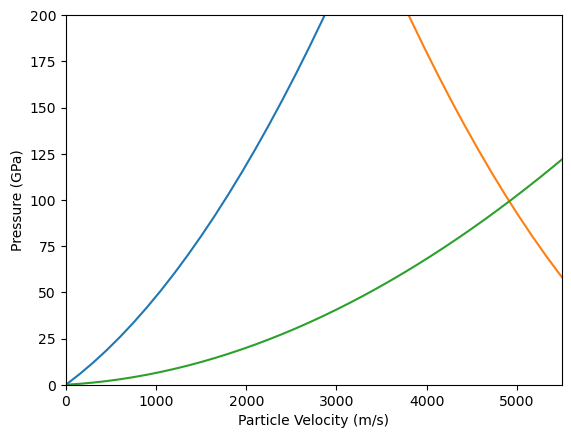

In [22]:
# import again because the silicabook import messed up the class
import IM_module as IM # classes and functions for this impedance match notebook

up =np.arange(101)/100.*15000

mat1 = IM.Material() # create material object named 'mat3'
matname='Steel304-l2' # material name in the material-data.csv file
mat1.DefineParamsID(matname,matdata,imat) # load the parameters for this material
mat1.MakeHugoniot(up)

mat2 = IM.Material() # create material object named 'mat3'
matname='Steel304-l2' # material name in the material-data.csv file
mat2.DefineParamsID(matname,matdata,imat) # load the parameters for this material
mat2.MakeHugoniot(up)

mat3 = IM.Material() # create material object named 'mat3'
#matname='Fused-qtz-R19L83' # material name in the material-data.csv file
matname='Fused-qtz-liq-2025' # material name in the material-data.csv file
mat3.DefineParamsID(matname,matdata,imat) # load the parameters for this material
mat3.MakeHugoniot(up)

# updated May 2025
# want 9.163+- 9.363 km/s shock velocity in the sample
#vel=7020 # 9.526 km/s
vel=6670  # shock vel 9.163 km/s
#vel=6330 # 8.80 km/s
#print(vel1-vel2)
plt.plot(mat2.hug.uparr,mat2.hug.parr/1.e9)
plt.plot(vel-mat1.hug.uparr,mat1.hug.parr/1.e9)
plt.plot(mat3.hug.uparr,mat3.hug.parr/1.e9)

plt.xlabel('Particle Velocity (m/s)')
plt.ylabel('Pressure (GPa)')
plt.ylim([0,200])
plt.xlim([0,5500])


IM12_success = mat1.IM_match(mat2,vel=vel,usemgmodelbool=True)
print(mat1.im1) # original flyer->driver IM
print(mat2.im1) # overwrites this state to new IM solution
IM23_success = mat2.IM_match(mat3,vel=mat2.im1.up*2,usemgmodelbool=True)
print(IM23_success)
print(mat1.im1) # original flyer->driver IM
print(mat2.im1) # overwrites this state to new IM solution
print('Target FS liq region')
print(mat3.im1) # target IM


plt.plot(2.*mat1.im1.up-mat2.isen.uparr,mat2.isen.parr/1.e9)
print(9.163-0.363)
print('Us = 9.163 km/s')
print('Us_low = 8.8 km/s')
print(9.163-0.363, 9.163+.363)
print(6670-6330,7020-6670)

## Shot 028: quartz stv region

Figure out the equivalent impact velocity to match the observed transit time in the NIR data. The velocity lasers are too poor.

This value and uncertainty manually entered in the master spreadsheet.

P = 149.75 (GPa), u<sub>p</sub> = 2.35 (km/s), U<sub>S</sub> = 0.0 (km/s), E = 2.77 (MJ/kg), &#961; = 11.1 (g/cm<sup>3</sup>)
P = 149.75 (GPa), u<sub>p</sub> = 2.35 (km/s), U<sub>S</sub> = 8.09 (km/s), E = 2.77 (MJ/kg), &#961; = 11.1 (g/cm<sup>3</sup>)
True
P = 149.75 (GPa), u<sub>p</sub> = 2.35 (km/s), U<sub>S</sub> = 0.0 (km/s), E = 2.77 (MJ/kg), &#961; = 11.1 (g/cm<sup>3</sup>)
P = 67.8 (GPa), u<sub>p</sub> = 3.39 (km/s), U<sub>S</sub> = 8.09 (km/s), E = 5.74 (MJ/kg), &#961; = 12.14 (g/cm<sup>3</sup>)
P = 67.8 (GPa), u<sub>p</sub> = 3.39 (km/s), U<sub>S</sub> = 7.55 (km/s), E = 5.74 (MJ/kg), &#961; = 4.81 (g/cm<sup>3</sup>)
7549.3936224103245
7.553 7.783 7.3229999999999995
200 200


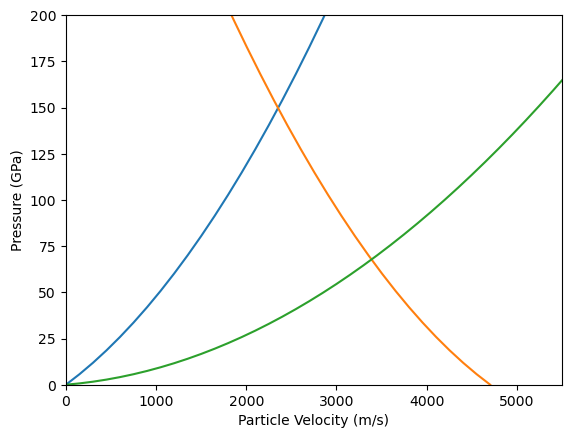

In [23]:
# import again because the silicabook import messed up the class
import IM_module as IM # classes and functions for this impedance match notebook

up =np.arange(101)/100.*15000

mat1 = IM.Material() # create material object named 'mat3'
matname='Steel304-l2' # material name in the material-data.csv file
mat1.DefineParamsID(matname,matdata,imat) # load the parameters for this material
mat1.MakeHugoniot(up)

mat2 = IM.Material() # create material object named 'mat3'
matname='Steel304-l2' # material name in the material-data.csv file
mat2.DefineParamsID(matname,matdata,imat) # load the parameters for this material
mat2.MakeHugoniot(up)

mat3 = IM.Material() # create material object named 'mat3'
#matname='qtz-CaCl2-region-2024' # material name in the material-data.csv file
#matname='qtz-CaCl2-region-2025' # material name in the material-data.csv file
matname='qtz-stv-region-2025' # material name in the material-data.csv file
mat3.DefineParamsID(matname,matdata,imat) # load the parameters for this material
mat3.MakeHugoniot(up)

#vel=4715 # 2024 value

#using cacl2 fit 2025
#vel=4785 # 2025 value to match Us = 7.553 km/s + 0.23
#vel=4700 # 2025 value to match Us = 7.553 km/s
#vel=4330 # 2025 value to match Us = 7.553 km/s - 0.23
# vel is 4.53 +- 0.225

#using stv fit 2025
#vel=4905 # 2025 value to match Us = 7.553 km/s + 0.23 = 7.783
vel=4705 # 2025 value to match Us = 7.553 km/s
#vel=4505 # 2025 value to match Us = 7.553 km/s - 0.23 = 7.32
# vel is 4.53 +- 0.225

#print(vel1-vel)
plt.plot(mat2.hug.uparr,mat2.hug.parr/1.e9)
plt.plot(vel-mat1.hug.uparr,mat1.hug.parr/1.e9)
plt.plot(mat3.hug.uparr,mat3.hug.parr/1.e9)

plt.xlabel('Particle Velocity (m/s)')
plt.ylabel('Pressure (GPa)')
plt.ylim([0,200])
plt.xlim([0,5500])


IM12_success = mat1.IM_match(mat2,vel=vel,usemgmodelbool=True)
print(mat1.im1) # original flyer->driver IM
print(mat2.im1) # overwrites this state to new IM solution
IM23_success = mat2.IM_match(mat3,vel=mat2.im1.up*2,usemgmodelbool=True)
print(IM23_success)
print(mat1.im1) # original flyer->driver IM
print(mat2.im1) # overwrites this state to new IM solution
print(mat3.im1) # target IM
print(mat3.im1.us)

plt.plot(2.*mat1.im1.up-mat2.isen.uparr,mat2.isen.parr/1.e9)
print(7.553,7.553+.23,7.553-0.23)
print(4705-4505,4905-4705)

## Shot 044: Quartz Stv region
Forward model this from impact velocity - not clear what the shock transit time is. Structured streak with poor time resolution.

Has steak data but no clear transit time (low time resolution streak and structured data).

USING qtz_hug_stv fit. May 2024. Switched to stv region.


P = 144.0 (GPa), u<sub>p</sub> = 2.29 (km/s), U<sub>S</sub> = 0.0 (km/s), E = 2.62 (MJ/kg), &#961; = 11.03 (g/cm<sup>3</sup>)
P = 144.0 (GPa), u<sub>p</sub> = 2.29 (km/s), U<sub>S</sub> = 7.99 (km/s), E = 2.62 (MJ/kg), &#961; = 11.03 (g/cm<sup>3</sup>)
True
P = 144.0 (GPa), u<sub>p</sub> = 2.29 (km/s), U<sub>S</sub> = 0.0 (km/s), E = 2.62 (MJ/kg), &#961; = 11.03 (g/cm<sup>3</sup>)
P = 64.85 (GPa), u<sub>p</sub> = 3.31 (km/s), U<sub>S</sub> = 7.99 (km/s), E = 5.47 (MJ/kg), &#961; = 12.07 (g/cm<sup>3</sup>)
P = 64.85 (GPa), u<sub>p</sub> = 3.31 (km/s), U<sub>S</sub> = 7.4 (km/s), E = 5.47 (MJ/kg), &#961; = 4.79 (g/cm<sup>3</sup>)
7400.885087170135
3306.574313792725
214.95769392223073


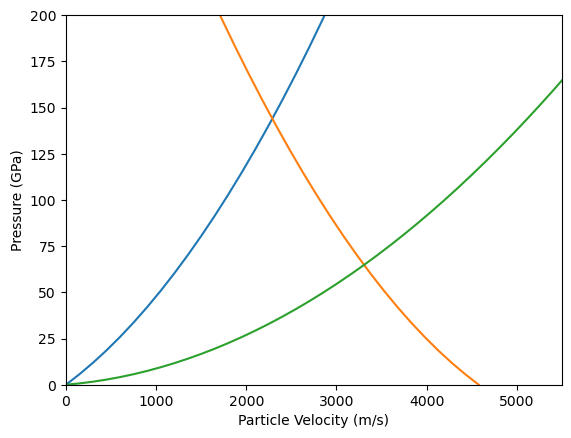

In [24]:
# import again because the silicabook import messed up the class
import IM_module as IM # classes and functions for this impedance match notebook

up =np.arange(101)/100.*15000

mat1 = IM.Material() # create material object named 'mat3'
matname='Steel304-l2' # material name in the material-data.csv file
mat1.DefineParamsID(matname,matdata,imat) # load the parameters for this material
mat1.MakeHugoniot(up)

mat2 = IM.Material() # create material object named 'mat3'
matname='Steel304-l2' # material name in the material-data.csv file
mat2.DefineParamsID(matname,matdata,imat) # load the parameters for this material
mat2.MakeHugoniot(up)

mat3 = IM.Material() # create material object named 'mat3'
#matname='qtz-CaCl2-region-2024' # material name in the material-data.csv file
matname='qtz-stv-region-2025' # material name in the material-data.csv file
mat3.DefineParamsID(matname,matdata,imat) # load the parameters for this material
mat3.MakeHugoniot(up)

#vel=4581
vel=4578 # +-.003 from MAVIS
#vel=4575
plt.plot(mat2.hug.uparr,mat2.hug.parr/1.e9)
plt.plot(vel-mat1.hug.uparr,mat1.hug.parr/1.e9)
plt.plot(mat3.hug.uparr,mat3.hug.parr/1.e9)

plt.xlabel('Particle Velocity (m/s)')
plt.ylabel('Pressure (GPa)')
plt.ylim([0,200])
plt.xlim([0,5500])


IM12_success = mat1.IM_match(mat2,vel=vel,usemgmodelbool=True)
print(mat1.im1) # original flyer->driver IM
print(mat2.im1) # overwrites this state to new IM solution
IM23_success = mat2.IM_match(mat3,vel=mat2.im1.up*2,usemgmodelbool=True)
print(IM23_success)
print(mat1.im1) # original flyer->driver IM
print(mat2.im1) # overwrites this state to new IM solution
print(mat3.im1) # target IM
print(mat3.im1.us)

plt.plot(2.*mat1.im1.up-mat2.isen.uparr,mat2.isen.parr/1.e9)

# calculate the error from linear fit with up
print(mat3.im1.up)
up = mat3.im1.up
#equation: f(x) = a[0] + a[1]*x
a = [1.52780599, 1.77602923]
cov = [[ 0.04306667, -0.01344138], [-0.01344138,  0.00423432]]
sig_us = np.sqrt(cov[0][0] + 2*cov[0][1]*up + up*up*cov[1][1])
print(sig_us)

# 7404, 7401, 7397

## Shot 032: quartz shot - poor everything. do not use.

Lots of problems with this shot. MAVIS did not work. Lasers are messy. Streak is extremely low temperature. NIR had scope problem with overwrite on IR1. NIR looks like it might have a multiwave structure and reflection.

Velocity 1 to 2 =  6.022 +/- 0.021 km/s<br>
Velocity 2 to 3 =  5.364 +/- 0.012 km/s<br>
Average Velocity = 5.693 +/- .330 km/s<p>

Lasers 2-3 velocity 5.364 km/s --> 83.56 GPa, should have a single shock velocity of 8.25 km/s

Visible channels had a shock velocity of about 8.7+-0.2 km/s --> impact velocity of vel=5774 m/s and P=94.2 GPa

This would be in the CaCl2 region of the alpha-qtz Hugoniot.

The temperatures are all over the place with no agreement between channels or the other data. So leaving out this experiments.




P = 201.85 (GPa), u<sub>p</sub> = 2.89 (km/s), U<sub>S</sub> = 0.0 (km/s), E = 4.17 (MJ/kg), &#961; = 11.66 (g/cm<sup>3</sup>)
P = 201.85 (GPa), u<sub>p</sub> = 2.89 (km/s), U<sub>S</sub> = 8.88 (km/s), E = 4.17 (MJ/kg), &#961; = 11.66 (g/cm<sup>3</sup>)
True
P = 201.85 (GPa), u<sub>p</sub> = 2.89 (km/s), U<sub>S</sub> = 0.0 (km/s), E = 4.17 (MJ/kg), &#961; = 11.66 (g/cm<sup>3</sup>)
P = 94.77 (GPa), u<sub>p</sub> = 4.08 (km/s), U<sub>S</sub> = 8.88 (km/s), E = 8.32 (MJ/kg), &#961; = 12.75 (g/cm<sup>3</sup>)
P = 94.77 (GPa), u<sub>p</sub> = 4.08 (km/s), U<sub>S</sub> = 8.76 (km/s), E = 8.32 (MJ/kg), &#961; = 4.96 (g/cm<sup>3</sup>)
8764.867921064653


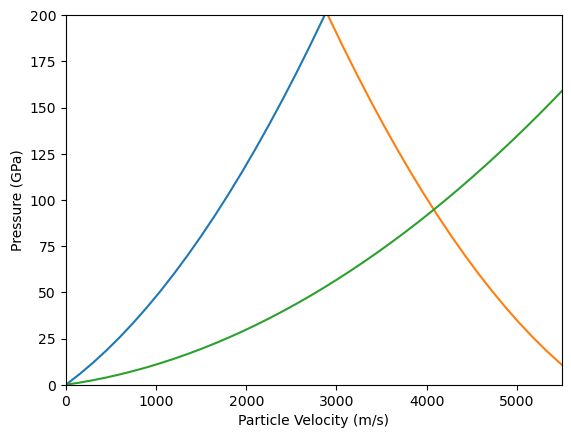

In [25]:
# import again because the silicabook import messed up the class
import IM_module as IM # classes and functions for this impedance match notebook

up =np.arange(101)/100.*15000

mat1 = IM.Material() # create material object named 'mat3'
matname='Steel304-l2' # material name in the material-data.csv file
mat1.DefineParamsID(matname,matdata,imat) # load the parameters for this material
mat1.MakeHugoniot(up)

mat2 = IM.Material() # create material object named 'mat3'
matname='Steel304-l2' # material name in the material-data.csv file
mat2.DefineParamsID(matname,matdata,imat) # load the parameters for this material
mat2.MakeHugoniot(up)

mat3 = IM.Material() # create material object named 'mat3'
matname='qtz-CaCl2-region-2025' # material name in the material-data.csv file
mat3.DefineParamsID(matname,matdata,imat) # load the parameters for this material
mat3.MakeHugoniot(up)

#vel1=6682
#vel=5364 # from laser 2 to 3
vel=5774 # from laser 2 to 3
#print(vel1-vel)
plt.plot(mat2.hug.uparr,mat2.hug.parr/1.e9)
plt.plot(vel-mat1.hug.uparr,mat1.hug.parr/1.e9)
plt.plot(mat3.hug.uparr,mat3.hug.parr/1.e9)

plt.xlabel('Particle Velocity (m/s)')
plt.ylabel('Pressure (GPa)')
plt.ylim([0,200])
plt.xlim([0,5500])


IM12_success = mat1.IM_match(mat2,vel=vel,usemgmodelbool=True)
print(mat1.im1) # original flyer->driver IM
print(mat2.im1) # overwrites this state to new IM solution
IM23_success = mat2.IM_match(mat3,vel=mat2.im1.up*2,usemgmodelbool=True)
print(IM23_success)
print(mat1.im1) # original flyer->driver IM
print(mat2.im1) # overwrites this state to new IM solution
print(mat3.im1) # target IM
print(mat3.im1.us)

plt.plot(2.*mat1.im1.up-mat2.isen.uparr,mat2.isen.parr/1.e9)


## Structured shocks

### Alpha-quartz:

65 GPa: Shots 27, 44 (streak only): very weird NIR data shape; definitely structured shock

70 GPa: Shot 28: structured release

83 GPa: Shot 48: structured NIR release

87.5 GPa: Shot 14: streak and NIR: looks spikey in streak; release normal; we should pull out the NIR data - not included at the moment. More evidence for wavelength variation or is it not calibratable?

102.4 GPa: Shot 47: streak has spikes on top; NIR looks more normal; if release wiggle, it is small; do all the wavelengths agree? no.

110 GPa: Shot 45: no NIR - tilt test; looks clean in streak

120 GPa: shot 33: looks ok but NIR does not agree in temps

123.9 GPa: shot 26: looks ok better agreement in temps; no 4.8 microns

### Fused silica

54.3 GPa: Shot 41 structured release

56.5 GPa: Shot 40; no temps from glue contamination; large error bar PV point

67.97 GPa: Shot 50: decaying shot; need to IM for shock pressure; vis and NIR do not agree

82.9 GPa: Shots 31 and 23: looks like clean release

84.3 GPa: shot 25: looks like clean release

87.2 GPa: Shot 60: decaying shock; has PDV shock velocity for PV state; no NIR

~94 GPa: Shot 32: poor velocity; no consistency between any temperature observation; recording problem for NIR. Leaving this experiment out.

94.2: GPa Shot 20 streak has a step during shock; release OK

99.6 GPa: Shot 22 streak has spikes on top; release OK

101.8 GPa: Shot 21: release looks OK. no streak

### Pressure determinations

Using IM-MC from impact velocity and shock velocity except:

Shot 22: FS liq region: poor lasers; use NIR for shock velocity and then fitted Hugoniot solution; shot record does not include target thickness metrology

Shot 28: qtz stv region: poor lasers; use NIR for shock velocity and then fitted Hugoniot solution

Shot 44: qtz stv region: multiwave shock front; use good MAVIS impact velocity with fitted Hugoniot to predict shock pressure

Shot 50: FS stv region: no shock velocity measured; using impact velocity with fitted Hugoniot to predict shock pressure. Model for shock decay




In [26]:
for i in range(len(silicadata_list)):
    print(silicadata_list[i].material)
for i in range(len(silicadata_list)):
    print(silicadata_list[i].ref)

['Z-cut Alpha-quartz']
['Fused Silica']
['Fused Silica']
['Fused Silica']
['Fused Silica']
['Fused Silica']
['Z-cut Alpha-quartz']
['Z-cut Alpha-quartz']
['Z-cut Alpha-quartz']
['Fused Silica']
['Z-cut Alpha-quartz']
['Fused Silica']
['Fused Silica']
['Z-cut Alpha-quartz']
['Z-cut Alpha-quartz']
['Z-cut Alpha-quartz']
['Z-cut Alpha-quartz']
['Fused Silica']
['Fused Silica']
['shot14']
['shot20']
['shot21']
['shot22']
['shot23']
['shot25']
['shot26']
['shot27']
['shot28']
['shot31']
['shot33']
['shot40']
['shot41']
['shot44']
['shot45']
['shot47']
['shot48']
['shot60']
['shot50']


## Make Latex Table


In [27]:
dict(qtz_list[0])

{'material': ['Z-cut Alpha-quartz'],
 'db_keys': ['filename',
  'datapath',
  'matid',
  'material',
  'formula',
  'rho_ref',
  'rho_ref_std',
  'rho_ref_units',
  'phase_ref'],
 'rho0': [np.float64(2.65)],
 'rho0_std': [np.float64(0.005)],
 'init_keys': ['m',
  'rho0',
  'rho0_std',
  'rho0_units',
  'P0',
  'P0_std',
  'P0_units',
  'T0',
  'T0_std',
  'T0_units',
  'phase0',
  'orientation'],
 'uflyer': [np.float64(5.467)],
 'uflyer_std': [np.float64(0.062)],
 'uflyer_units': ['km/s'],
 'up': [np.float64(3.8997608821055123)],
 'up_std': [np.float64(0.048632916397201215)],
 'up_units': ['km/s'],
 'us': [np.float64(8.46)],
 'us_std': [np.float64(0.015)],
 'us_units': ['km/s'],
 'P': [np.float64(87.43147985491223)],
 'P_std': [np.float64(1.0942857843844278)],
 'P_units': ['GPa'],
 'rho': [np.float64(4.916686588509419)],
 'rho_std': [np.float64(0.05386219439000621)],
 'rho_units': ['g/cm3'],
 'T': [np.float64(4661.0)],
 'T_std': [np.float64(172.0)],
 'T_source': ['streak'],
 'T_rel': [

In [28]:
for i in range(len(qtz_list)):
    print(qtz_list[i].ref)

['shot14']
['shot26']
['shot27']
['shot28']
['shot33']
['shot44']
['shot45']
['shot47']
['shot48']


In [29]:
def formatstr(val,err,n):
    #print(val,err,n)
    #print(str(int(np.round(val*np.pow(10,n))))[-1:])
    if str(int(np.round(val*np.pow(10,n))))[-1:] == '0':
        sss=(str(np.round(val*np.pow(10,n))/np.pow(10,n))+'0 ± '+str(np.round(err*np.pow(10,n))/np.pow(10,n)))
    else:
        sss=(str(np.round(val*np.pow(10,n))/np.pow(10,n))+' ± '+str(np.round(err*np.pow(10,n))/np.pow(10,n)))
    if n == 0:
        sss=(str(int(np.round(val*np.pow(10,n))))+' ± '+str(int(np.round(err*np.pow(10,n)))))
        
    return sss

In [30]:
IM_list = ['shot22','shot28','shot44','shot50']
decay_list = ['shot50','shot60']
cu_list = ['shot50']

isort = np.argsort(np.asarray(qtz_p_list))
print(isort)
for i in isort:
    print(i,qtz_p_list[i],qtz_list[i].ref[0],qtz_list[i].rho0[0],qtz_list[i].rho0_std[0],qtz_list[i].uflyer[0],qtz_list[i].uflyer_std[0],qtz_list[i].P[0],qtz_list[i].P_std[0],qtz_list[i].us[0],qtz_list[i].us_std[0],qtz_list[i].up[0],qtz_list[i].up_std[0],qtz_list[i].rho[0],qtz_list[i].rho_std[0],qtz_list[i].T[0],qtz_list[i].T_std[0])

print('latex quartz')
isort = np.argsort(np.asarray(qtz_p_list))
print(isort)
for i in isort:
    sss = qtz_list[i].ref[0]
    slabel = sss[4::]
    if sss in IM_list:
        slabel += '*'
    #print(slabel,sss)
    print(formatstr(qtz_list[i].rho0[0],qtz_list[i].rho0_std[0],3),' & ', formatstr(qtz_list[i].uflyer[0],qtz_list[i].uflyer_std[0],3),' & ',formatstr(qtz_list[i].P[0],qtz_list[i].P_std[0],1),' & ',formatstr(qtz_list[i].us[0],qtz_list[i].us_std[0],3),' & ',formatstr(qtz_list[i].up[0],qtz_list[i].up_std[0],3),' & ',formatstr(qtz_list[i].rho[0],qtz_list[i].rho_std[0],3),' & ',formatstr(qtz_list[i].T[0],qtz_list[i].T_std[0],0),' & ',slabel,' \\\ % '+sss)

print('latex fused silica')
isort = np.argsort(np.asarray(fs_p_list))
print(isort)
for i in isort:
    sss = fs_list[i].ref[0]
    slabel = sss[4::]
    if sss in IM_list:
        slabel += '*'
    if sss in decay_list:
        slabel += '‡'
    if sss in cu_list:
        slabel += '†'
    #print(slabel,sss)
    print(formatstr(fs_list[i].rho0[0],fs_list[i].rho0_std[0],3),' & ', formatstr(fs_list[i].uflyer[0],fs_list[i].uflyer_std[0],3),' & ',formatstr(fs_list[i].P[0],fs_list[i].P_std[0],1),' & ',formatstr(fs_list[i].us[0],fs_list[i].us_std[0],3),' & ',formatstr(fs_list[i].up[0],fs_list[i].up_std[0],3),' & ',formatstr(fs_list[i].rho[0],fs_list[i].rho_std[0],3),' & ',formatstr(fs_list[i].T[0],fs_list[i].T_std[0],0),' & ',slabel,' \\\ % '+sss)
print('Shot 50 had copper flyer; the rest were SS304')


[5 2 3 8 0 7 6 4 1]
5 65.00989408020008 shot44 2.641 0.002 4.578 0.003 65.00989408020008 1.387261742681314 7.401 0.215 3.328034804733974 0.022332871577851524 4.808365823462667 0.13759935767613615 3480.0 60.0
2 65.10390400961398 shot27 2.641 0.002 4.569 0.101 65.10390400961398 1.568197906359395 7.43 0.052 3.3175878348893604 0.07753371810261639 4.773382354709332 0.0948829069457645 3412.766828 91.982392
3 68.21054891984602 shot28 2.65 0.002 4.705 0.2 68.21054891984602 3.390280285391994 7.553 0.23 3.4089605189223633 0.15335146606759317 4.8463428366516865 0.23386954094301196 4142.510301 169.457238
8 82.99306752903478 shot48 2.651 0.003 5.278 0.004 82.99306752903478 0.13391546642529276 8.2994 0.0042 3.772141601908614 0.0052519638765062574 4.859850448829426 0.007571349686829736 4136.765735 169.151493
0 87.43147985491223 shot14 2.65 0.005 5.467 0.062 87.43147985491223 1.0942857843844278 8.46 0.015 3.8997608821055123 0.048632916397201215 4.916686588509419 0.05386219439000621 4661.0 172.0
7 102.

<>:19: SyntaxWarning: invalid escape sequence '\ '
<>:34: SyntaxWarning: invalid escape sequence '\ '
<>:19: SyntaxWarning: invalid escape sequence '\ '
<>:34: SyntaxWarning: invalid escape sequence '\ '
/var/folders/4z/xws_ywgj78sc494vpwymn9bw0000gn/T/ipykernel_24715/1271822705.py:19: SyntaxWarning: invalid escape sequence '\ '
  print(formatstr(qtz_list[i].rho0[0],qtz_list[i].rho0_std[0],3),' & ', formatstr(qtz_list[i].uflyer[0],qtz_list[i].uflyer_std[0],3),' & ',formatstr(qtz_list[i].P[0],qtz_list[i].P_std[0],1),' & ',formatstr(qtz_list[i].us[0],qtz_list[i].us_std[0],3),' & ',formatstr(qtz_list[i].up[0],qtz_list[i].up_std[0],3),' & ',formatstr(qtz_list[i].rho[0],qtz_list[i].rho_std[0],3),' & ',formatstr(qtz_list[i].T[0],qtz_list[i].T_std[0],0),' & ',slabel,' \\\ % '+sss)
/var/folders/4z/xws_ywgj78sc494vpwymn9bw0000gn/T/ipykernel_24715/1271822705.py:34: SyntaxWarning: invalid escape sequence '\ '
  print(formatstr(fs_list[i].rho0[0],fs_list[i].rho0_std[0],3),' & ', formatstr(fs_list[

In [32]:
# end of notebook